# DBLP Conference Mining Team 7 Notebook

Objective: Menganalisis popularitas konferensi dan menemukan pola asosiasi antar-konferensi dari publikasi inproceedings DBLP 2015-2025 dengan Apriori dan FP-Growth, dinilai dari jumlah frequent itemset, jumlah association rule, dan waktu eksekusi.

# Sinkronisasi versi modules dan libraries

In [85]:
import sys
print(sys.version)
%pip install -q pandas==2.3.3 numpy==2.4.4 matplotlib==3.10.9 lxml==6.1.3

3.12.10 (tags/v3.12.10:0cc8128, Apr  8 2025, 12:21:36) [MSC v.1943 64 bit (AMD64)]
Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 26.1.2 -> 26.3
[notice] To update, run: C:\Users\leouw\AppData\Local\Microsoft\WindowsApps\PythonSoftwareFoundation.Python.3.12_qbz5n2kfra8p0\python.exe -m pip install --upgrade pip


# Import modules dan libraries

In [86]:
from collections import Counter, defaultdict
from dataclasses import dataclass
from datetime import datetime, timezone
from itertools import combinations
from pathlib import Path
import gzip
import json
import math
import platform
import re
import sqlite3
import statistics
import time
import unicodedata

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import display
from lxml import etree

# Import datasets

## Snapshot DBLP

### Sumber dan tanggal pengambilan
Snapshot DBLP diunduh satu kali di luar notebook dan disimpan di `data/raw/`, notebook tidak pernah mengunduh ulang, sehingga isi datanya tetap dan angka laporan tidak berubah antar-run. Tanggal pengambilan dan ukuran file dibaca dari `data/raw/metadata.json`.

In [87]:
SNAPSHOT_DATE = "2026-11-16"
ROOT = Path.cwd()
if ROOT.name == "notebooks":
    ROOT = ROOT.parent
SNAPSHOT_DIR = ROOT / "data" / "raw"
SNAPSHOT_GZ = SNAPSHOT_DIR / "dblp.xml.gz"
DTD = SNAPSHOT_DIR / "dblp.dtd"
OUT = ROOT / "data" / "processed"
RESULTS = ROOT / "results" / "main"
for folder in (OUT, RESULTS):
    folder.mkdir(parents=True, exist_ok=True)

metadata_file = SNAPSHOT_DIR / "metadata.json"
assert metadata_file.exists(), f"Snapshot belum ada di {SNAPSHOT_DIR}, unduh dblp.xml.gz dan dblp.dtd beserta metadata.json lebih dulu"
snapshot = json.loads(metadata_file.read_text(encoding="utf-8"))
assert SNAPSHOT_GZ.stat().st_size == snapshot["size_bytes"], "Ukuran dblp.xml.gz tidak sama dengan metadata.json"
assert DTD.exists(), f"dblp.dtd tidak ada di {SNAPSHOT_DIR}"

print("Sumber:", snapshot["source"])
print("Tanggal pengambilan:", snapshot["retrieved_at"])
print("Data sampai:", datetime.strptime(SNAPSHOT_DATE, "%Y-%m-%d").strftime("%d/%m/%Y"))
print("Terakhir diubah di server DBLP:", snapshot["last_modified"])
print("Ukuran gzip (GB):", round(snapshot["size_bytes"] / 1e9, 2))

Sumber: https://dblp.org/xml/dblp.xml.gz
Tanggal pengambilan: 2026-11-16 14:46 UTC
Data sampai: 16/11/2026
Terakhir diubah di server DBLP: Sun, 15 Nov 2026 22:40:21 GMT
Ukuran gzip (GB): 1.12


### Parameter eksperimen
Periode pengamatan sesuai soal, empat nilai minimum support untuk Task 4-6, minimum confidence 50%, support untuk analisis temporal, dan jumlah pengulangan pengukuran waktu mining (diambil mediannya). `VENUE_ALIASES` menyatukan NIPS (nama 2015-2017) dengan NeurIPS (nama sejak 2018) karena keduanya konferensi yang sama.

In [88]:
YEAR_MIN, YEAR_MAX = 2015, 2025
SUPPORTS = [0.001, 0.005, 0.01, 0.02]
MIN_CONFIDENCE = 0.50
TEMPORAL_SUPPORT = 0.005
RUNTIME_REPEATS = 3
VENUE_ALIASES = {"NIPS": "NeurIPS"}

print("Periode:", YEAR_MIN, "-", YEAR_MAX)
print("Minimum support:", SUPPORTS)
print("Minimum confidence:", MIN_CONFIDENCE)
print("Minimum support temporal:", TEMPORAL_SUPPORT)
print("Pengulangan pengukuran waktu:", RUNTIME_REPEATS)

Periode: 2015 - 2025
Minimum support: [0.001, 0.005, 0.01, 0.02]
Minimum confidence: 0.5
Minimum support temporal: 0.005
Pengulangan pengukuran waktu: 3


## Ekstraksi XML

### Fungsi pembaca teks
Fungsi untuk membaca teks elemen XML apa adanya dan untuk membersihkan teks (Unicode NFKC dan spasi). Pembacaan mentah dipisah dari pembersihan agar setiap keputusan preprocessing terlihat di Task 1.

In [89]:
RECORD_TAGS = ("article", "inproceedings", "proceedings", "book", "incollection", "phdthesis", "mastersthesis", "www", "person", "data")
NON_ALNUM = re.compile(r"[\W_]+")


def clean_text(value):
    return re.sub(r"\s+", " ", unicodedata.normalize("NFKC", value or "")).strip()


def raw_text(element, tag):
    child = element.find(tag)
    return "".join(child.itertext()) if child is not None else None


def normalize_author(value):
    return clean_text(value)


def normalize_venue(value):
    name = clean_text(value)
    return VENUE_ALIASES.get(name, name)


def normalize_title(value):
    return NON_ALNUM.sub("", (value or "").casefold())


print("Tag record yang dihitung:", ", ".join(RECORD_TAGS))

Tag record yang dihitung: article, inproceedings, proceedings, book, incollection, phdthesis, mastersthesis, www, person, data


### Tabel mentah
Membuat database SQLite berisi dua tabel mentah: `raw_inproceedings` (satu baris per record) dan `raw_authors` (satu baris per author pada record). Ekstraksi dilewati jika database dan ringkasannya sudah ada. Database dari ekstraksi yang terputus dipindahkan ke file `.incomplete-...` (tidak dihapus) lalu ekstraksi diulang. Cache SQLite dinaikkan menjadi sekitar 2 GB dan tabel sementara disimpan di memori, karena dengan cache bawaan (2 MB) langkah normalisasi author berjalan puluhan menit.

In [90]:
DB = OUT / "dblp_inproceedings.sqlite"
TYPES_JSON = RESULTS / "record_types.json"
PROFILE_JSON = RESULTS / "inproceedings_profile.json"

extraction_done = DB.exists() and TYPES_JSON.exists() and PROFILE_JSON.exists()
if DB.exists() and not extraction_done:
    incomplete = DB.with_name(f"{DB.stem}.incomplete-{datetime.now():%Y%m%d-%H%M%S}{DB.suffix}")
    DB.rename(incomplete)
    print("Ekstraksi sebelumnya tidak selesai, database dipindahkan (tidak dihapus) ke", incomplete.name)
con = sqlite3.connect(DB)
con.execute("PRAGMA cache_size = -2000000")
con.execute("PRAGMA temp_store = MEMORY")
if not extraction_done:
    con.executescript("""
        CREATE TABLE raw_inproceedings (dblp_key TEXT, title TEXT, year TEXT, booktitle TEXT);
        CREATE TABLE raw_authors (dblp_key TEXT, author TEXT);
    """)
print("Ekstraksi sudah selesai sebelumnya" if extraction_done else "Tabel mentah dibuat")

Ekstraksi sudah selesai sebelumnya


### Membaca XML
Membaca `dblp.xml.gz` satu kali secara bertahap. Setiap record dihitung per jenisnya, dan hanya record `inproceedings` yang disimpan ke tabel mentah tanpa diubah.

In [91]:
if extraction_done:
    print("Ekstraksi dilewati, database sudah ada:", DB)
else:
    type_counts, field_counts = Counter(), Counter()
    sample_xml = None
    pending_pub, pending_auth = [], []

    def flush():
        con.executemany("INSERT INTO raw_inproceedings VALUES (?,?,?,?)", pending_pub)
        con.executemany("INSERT INTO raw_authors VALUES (?,?)", pending_auth)
        con.commit()
        pending_pub.clear()
        pending_auth.clear()

    parser = etree.XMLPullParser(events=("end",), tag=RECORD_TAGS, load_dtd=True, resolve_entities=True,
                                 no_network=True, huge_tree=True, base_url=str(SNAPSHOT_DIR / "dblp.xml"))
    with gzip.open(SNAPSHOT_GZ, "rb") as stream:
        while chunk := stream.read(1 << 24):
            parser.feed(chunk)
            for _, el in parser.read_events():
                type_counts[el.tag] += 1
                if el.tag == "inproceedings":
                    key, year = el.get("key"), raw_text(el, "year")
                    field_counts.update(set(el.attrib) | {child.tag for child in el})
                    pending_pub.append((key, raw_text(el, "title"), year, raw_text(el, "booktitle")))
                    pending_auth.extend((key, "".join(a.itertext())) for a in el.findall("author"))
                    if sample_xml is None and year and year.strip().isdigit() and YEAR_MIN <= int(year) <= YEAR_MAX:
                        sample_xml = etree.tostring(el, encoding="unicode", with_tail=False)
                el.clear()
                while el.getprevious() is not None:
                    del el.getparent()[0]
            if len(pending_pub) >= 20000:
                flush()
    flush()
    TYPES_JSON.write_text(json.dumps(dict(type_counts.most_common()), indent=2), encoding="utf-8")
    PROFILE_JSON.write_text(json.dumps({"fields": dict(field_counts), "sample_xml": sample_xml}, indent=2, ensure_ascii=False), encoding="utf-8")
    print("Ekstraksi selesai:", dict(type_counts.most_common()))

Ekstraksi dilewati, database sudah ada: c:\MyFolder\Kuliah\Semester 7\Data Mining\Tubes\dblp-conference-mining-team-7\data\processed\dblp_inproceedings.sqlite


### Indeks tabel mentah
Membuat indeks pada `dblp_key` agar pencarian author per paper cepat pada langkah preprocessing.

In [92]:
con.execute("CREATE INDEX IF NOT EXISTS idx_raw_pub_key ON raw_inproceedings (dblp_key)")
con.execute("CREATE INDEX IF NOT EXISTS idx_raw_auth_key ON raw_authors (dblp_key)")
con.commit()
pd.Series({
    "raw_inproceedings (record)": con.execute("SELECT COUNT(*) FROM raw_inproceedings").fetchone()[0],
    "raw_authors (pasangan paper-author)": con.execute("SELECT COUNT(*) FROM raw_authors").fetchone()[0],
}).to_frame("baris")

,baris
raw_inproceedings (record),4001131
raw_authors (pasangan paper-author),13990816


### Fungsi SQL dan log preprocessing
Mendaftarkan fungsi pembersihan teks ke SQLite supaya langkah preprocessing bisa ditulis sebagai query, dan menyiapkan log jumlah record sebelum dan sesudah setiap langkah.

In [93]:
con.create_function("clean_text", 1, clean_text, deterministic=True)
con.create_function("normalize_venue", 1, normalize_venue, deterministic=True)
con.create_function("normalize_title", 1, normalize_title, deterministic=True)
preprocessing_log = []


def count_rows(table):
    return con.execute(f"SELECT COUNT(*) FROM {table}").fetchone()[0]


def log_step(step, before, after, note):
    preprocessing_log[:] = [row for row in preprocessing_log if row["langkah"] != step]
    preprocessing_log.append({"langkah": step, "sebelum": before, "sesudah": after, "dibuang": before - after, "keterangan": note})
    print(f"{step}: {before:,} -> {after:,} record (dibuang {before - after:,})")

# Task 1 - Data Understanding and Preprocessing

## 1. Eksplorasi dataset
Menjelaskan struktur dataset, atribut, jumlah record, dan jenis publikasi yang tersedia.

### Struktur dataset
Dump berupa satu file XML dengan elemen root `<dblp>` yang berisi record satu per satu. Setiap record punya atribut `key` (identitas unik yang memuat kode venue, misalnya `conf/nips/...`) dan `mdate` (tanggal record diubah), lalu elemen isi seperti pada contoh record `inproceedings` berikut.

In [94]:
profile = json.loads(PROFILE_JSON.read_text(encoding="utf-8"))
record_types = pd.Series(json.loads(TYPES_JSON.read_text(encoding="utf-8")), name="records").sort_values(ascending=False)
n_inproceedings = int(record_types["inproceedings"])
print(profile["sample_xml"])

<inproceedings mdate="2025-01-19" key="conf/dac/RoquetSRTSK24">
<author orcid="0009-0001-8458-516X">Lucas Roquet</author>
<author orcid="0000-0002-3504-9862">Fernando Fernandes dos Santos</author>
<author orcid="0000-0002-0821-1879">Paolo Rech</author>
<author orcid="0000-0003-1484-5162">Marcello Traiola</author>
<author orcid="0000-0003-4334-6418">Olivier Sentieys</author>
<author orcid="0000-0002-9293-469X">Angeliki Kritikakou</author>
<title>Cross-Layer Reliability Evaluation and Efficient Hardening of Large Vision Transformers Models.</title>
<pages>291:1-291:6</pages>
<year>2024</year>
<booktitle>DAC</booktitle>
<ee>https://doi.org/10.1145/3649329.3655688</ee>
<ee>https://www.wikidata.org/entity/Q131132528</ee>
<crossref>conf/dac/2024</crossref>
<url>db/conf/dac/dac2024.html#RoquetSRTSK24</url>
</inproceedings>


### Atribut dataset
Atribut pada record `inproceedings` beserta jumlah record yang mengisinya. Atribut yang dipakai analisis:
- key: identitas unik record, memuat kode venue.
- author: penulis paper, nol atau lebih per record.
- title: judul paper.
- year: tahun acara konferensi.
- booktitle: nama prosiding, dipakai sebagai nama venue.

Atribut lain (`pages`, `ee`, `url`, `crossref`, dan seterusnya) tidak relevan untuk popularitas dan pola asosiasi.

In [95]:
USED_ATTRIBUTES = ["key", "author", "title", "year", "booktitle"]
attributes = pd.Series(profile["fields"], name="records_with_value").to_frame()
attributes["missing"] = n_inproceedings - attributes["records_with_value"]
attributes["missing_%"] = (attributes["missing"] / n_inproceedings * 100).round(3)
attributes["used"] = attributes.index.isin(USED_ATTRIBUTES)
attributes = attributes.sort_values(["used", "records_with_value"], ascending=False)
attributes

,records_with_value,missing,missing_%,used
title,4001131,0,0.000,True
year,4001131,0,0.000,True
key,4001131,0,0.000,True
booktitle,4000810,321,0.008,True
author,3995049,6082,0.152,True
url,4001131,0,0.000,False
mdate,4001131,0,0.000,False
crossref,3998522,2609,0.065,False
ee,3863752,137379,3.434,False
pages,3771703,229428,5.734,False


### Jumlah record
Jumlah record pada dump, berapa banyak di antaranya yang berjenis `inproceedings`, dan jumlah pasangan paper-author di dalamnya.

In [96]:
total_records = int(record_types.sum())
pd.Series({
    "record pada dump (semua jenis)": total_records,
    "record inproceedings": n_inproceedings,
    "porsi inproceedings (%)": round(n_inproceedings / total_records * 100, 2),
    "pasangan paper-author pada inproceedings": count_rows("raw_authors"),
}).to_frame("nilai")

,nilai
record pada dump (semua jenis),13112101.00
record inproceedings,4001131.00
porsi inproceedings (%),30.51
pasangan paper-author pada inproceedings,13990816.00


### Jenis publikasi
Jumlah record per jenis publikasi pada seluruh dump. Jenis yang ada:
- article: paper jurnal.
- www: halaman profil author.
- inproceedings: paper konferensi dan workshop.
- phdthesis dan mastersthesis: disertasi doktor dan tesis magister.
- incollection: bab dalam buku.
- proceedings: data prosiding itu sendiri, bukan paper di dalamnya.
- book: buku.
- data: dataset penelitian.

In [97]:
record_type_table = record_types.to_frame()
record_type_table["share_%"] = (record_type_table["records"] / total_records * 100).round(2)
record_type_table

,records,share_%
article,4519980,34.47
www,4242364,32.35
inproceedings,4001131,30.51
phdthesis,158395,1.21
incollection,71264,0.54
proceedings,65856,0.50
data,31430,0.24
book,21654,0.17
mastersthesis,27,0.00


## 2. Preprocessing
Membersihkan record `inproceedings` menjadi tabel `publications` (satu baris per paper) dan `authorship` (satu baris per pasangan paper dan author). Langkah dijalankan berurutan dan setiap langkah mencatat jumlah record yang dibuang. Tahun difilter lebih awal karena langkah ini yang paling banyak mengurangi data, sehingga langkah sesudahnya lebih ringan.

### Memilih publikasi konferensi dan workshop
Hanya record `inproceedings` yang dipakai karena itu jenis record DBLP untuk paper konferensi dan workshop. Jurnal, buku, dan halaman profil tidak punya venue konferensi sehingga tidak bisa menjadi item. Pemilihan terjadi saat ekstraksi, langkah ini menyalin hasilnya ke tabel kerja `publications`.

In [98]:
con.executescript("""
DROP TABLE IF EXISTS publications;
DROP TABLE IF EXISTS authorship;
CREATE TABLE publications (dblp_key TEXT, title TEXT, year INTEGER, booktitle TEXT, venue TEXT);
CREATE TABLE authorship (dblp_key TEXT, author TEXT);
INSERT INTO publications (dblp_key, title, year, booktitle)
    SELECT dblp_key, title, TRIM(year), booktitle FROM raw_inproceedings;
CREATE INDEX idx_publications_key ON publications (dblp_key);
""")
log_step("Memilih konferensi dan workshop", total_records, count_rows("publications"), "hanya record inproceedings")

Memilih konferensi dan workshop: 13,112,101 -> 4,001,131 record (dibuang 9,110,970)


### Konsistensi atribut tahun
`year` dibaca sebagai integer dan hanya tahun 2015-2025 yang dipakai, agar tahun bisa dibandingkan sebagai angka dan sesuai periode pengamatan. Record dengan tahun yang bukan angka atau di luar periode dibuang.

In [ ]:
before = count_rows("publications")
con.execute("DELETE FROM publications WHERE typeof(year) <> 'integer' OR year NOT BETWEEN ? AND ?", (YEAR_MIN, YEAR_MAX))
con.commit()
log_step("Konsistensi tahun", before, count_rows("publications"), f"year integer {YEAR_MIN}-{YEAR_MAX}")
pd.read_sql_query("SELECT MIN(year) AS year_min, MAX(year) AS year_max, COUNT(DISTINCT year) AS n_years FROM publications", con)

### Menangani missing values
Record tanpa key, title, booktitle (venue), atau author dibuang karena tanpa salah satunya record tidak bisa menjadi transaksi, dan jumlahnya terlalu kecil untuk memengaruhi hasil.

In [ ]:
before = count_rows("publications")
without_text = con.execute("""
    DELETE FROM publications WHERE dblp_key IS NULL OR title IS NULL OR TRIM(title) = ''
        OR booktitle IS NULL OR TRIM(booktitle) = ''
""").rowcount
without_author = con.execute("""
    DELETE FROM publications WHERE NOT EXISTS (
        SELECT 1 FROM raw_authors a WHERE a.dblp_key = publications.dblp_key AND TRIM(a.author) <> '')
""").rowcount
con.commit()
print(f"Dibuang karena key, title, atau booktitle kosong: {without_text:,}")
print(f"Dibuang karena tidak punya author: {without_author:,}")
log_step("Menangani missing values", before, count_rows("publications"), "tanpa key, title, booktitle, atau author")

Dibuang karena key, title, atau booktitle kosong: 190
Dibuang karena tidak punya author: 2,255
Menangani missing values: 2,004,019 -> 2,001,574 record (dibuang 2,445)


### Normalisasi nama author
Normalisasi Unicode (NFKC) dan spasi pada nama author, lalu setiap pasangan paper-author disimpan sekali. Suffix homonim DBLP seperti "Wei Wang 0001" dipertahankan karena itu penanda orang yang berbeda, kalau dihapus banyak peneliti berbeda tergabung menjadi satu author.

In [ ]:
before = count_rows("publications")
con.execute("DELETE FROM authorship")
con.execute("""
    INSERT INTO authorship (dblp_key, author)
    SELECT DISTINCT dblp_key, author FROM (
        SELECT p.dblp_key AS dblp_key, clean_text(a.author) AS author
        FROM publications p JOIN raw_authors a ON a.dblp_key = p.dblp_key
    ) WHERE author <> ''
""")
con.execute("CREATE INDEX IF NOT EXISTS idx_authorship_key ON authorship (dblp_key)")
con.execute("CREATE INDEX IF NOT EXISTS idx_authorship_author ON authorship (author)")
without_author = con.execute("""
    DELETE FROM publications WHERE NOT EXISTS (SELECT 1 FROM authorship a WHERE a.dblp_key = publications.dblp_key)
""").rowcount
con.commit()
names_clean = con.execute("SELECT COUNT(DISTINCT author) FROM authorship").fetchone()[0]
homonyms = pd.read_sql_query("SELECT DISTINCT author FROM authorship WHERE author GLOB '* [0-9][0-9][0-9][0-9]'", con)
print(f"Author unik setelah normalisasi: {names_clean:,}")
print(f"Author dengan suffix homonim: {len(homonyms):,}, paper tanpa author valid dibuang: {without_author:,}")
log_step("Normalisasi nama author", before, count_rows("publications"), f"{names_clean:,} author unik")
homonyms.head(5)

Author unik setelah normalisasi: 1,822,238
Author dengan suffix homonim: 90,351, paper tanpa author valid dibuang: 0
Normalisasi nama author: 2,001,574 -> 2,001,574 record (dibuang 0)


,author
0,A Pranav 0001
1,A. A. Bini 0001
2,A. A. Zaidan 0001
3,A. Ahilan 0001
4,A. Anjali 0001


### Normalisasi nama conference/venue
Nama venue diambil dari `booktitle` setelah Unicode dan spasi dirapikan, lalu `VENUE_ALIASES` diterapkan (NIPS menjadi NeurIPS). Tabel di bawah mengaudit nama lain yang tampak sinonim, misalnya variasi nomor jilid dalam tanda kurung seperti "ECCV (1)" dan "ECCV (2)".

In [ ]:
before = count_rows("publications")
con.execute("UPDATE publications SET venue = normalize_venue(booktitle)")
empty_venue = con.execute("DELETE FROM publications WHERE venue = ''").rowcount
con.commit()
venues = pd.read_sql_query("SELECT venue, COUNT(*) AS publications FROM publications GROUP BY venue", con)
venues["base_name"] = venues["venue"].str.replace(r"\s*\(.*\)\s*$", "", regex=True)
variants = venues.groupby("base_name").agg(variants=("venue", "nunique"), publications=("publications", "sum"))
booktitles = con.execute("SELECT COUNT(DISTINCT booktitle) FROM publications").fetchone()[0]
aliased = con.execute("SELECT COUNT(*) FROM publications WHERE booktitle <> venue AND booktitle IN (%s)" % ",".join("?" * len(VENUE_ALIASES)), list(VENUE_ALIASES)).fetchone()[0]
print(f"Paper yang namanya diganti lewat alias {VENUE_ALIASES}: {aliased:,}")
print(f"Booktitle mentah: {booktitles:,} -> venue: {len(venues):,}, nama dasar unik setelah tanda kurung dibuang: {len(variants):,}")
log_step("Normalisasi nama venue", before, count_rows("publications"), f"{booktitles:,} booktitle -> {len(venues):,} venue")
variants.sort_values("variants", ascending=False).head(10)

Paper yang namanya diganti lewat alias {'NIPS': 'NeurIPS'}: 1,646
Booktitle mentah: 8,903 -> venue: 8,902, nama dasar unik setelah tanda kurung dibuang: 7,041
Normalisasi nama venue: 2,001,574 -> 2,001,574 record (dibuang 0)


,variants,publications
base_name,,
ECCV,89,6580
HCI,86,19913
ICPR,41,4627
ICIC,36,4152
ICCSA,26,4177
AHFE,25,4285
ECCV Workshops,24,1719
PRCV,18,2728
MICCAI,17,5934


### Menghilangkan data duplikat
Record dianggap duplikat jika `key`-nya sama, atau judul (huruf kecil tanpa tanda baca), kumpulan author, venue, dan tahunnya sama. Hanya record pertama yang disimpan, karena satu paper tidak boleh dihitung dua kali.

In [ ]:
before = count_rows("publications")
same_key = con.execute("DELETE FROM publications WHERE rowid NOT IN (SELECT MIN(rowid) FROM publications GROUP BY dblp_key)").rowcount
con.execute("DROP TABLE IF EXISTS temp.author_signature")
con.execute("""
    CREATE TEMP TABLE author_signature AS
    SELECT dblp_key, group_concat(author, '|') AS authors
    FROM (SELECT dblp_key, author FROM authorship ORDER BY dblp_key, author)
    GROUP BY dblp_key
""")
same_content = con.execute("""
    DELETE FROM publications WHERE rowid IN (
        SELECT rowid FROM (
            SELECT p.rowid AS rowid, ROW_NUMBER() OVER (
                PARTITION BY normalize_title(p.title), s.authors, p.venue, p.year ORDER BY p.rowid) AS rn
            FROM publications p JOIN temp.author_signature s ON s.dblp_key = p.dblp_key
        ) WHERE rn > 1
    )
""").rowcount
orphans = con.execute("""
    DELETE FROM authorship WHERE NOT EXISTS (SELECT 1 FROM publications p WHERE p.dblp_key = authorship.dblp_key)
""").rowcount
con.commit()
print(f"Dibuang karena key sama: {same_key:,}")
print(f"Dibuang karena judul, author, venue, dan tahun sama: {same_content:,}")
print(f"Baris authorship milik paper yang dibuang: {orphans:,}")
log_step("Menghilangkan data duplikat", before, count_rows("publications"), "key sama atau judul, author, venue, tahun sama")

Dibuang karena key sama: 0
Dibuang karena judul, author, venue, dan tahun sama: 683
Baris authorship milik paper yang dibuang: 2,471
Menghilangkan data duplikat: 2,001,574 -> 2,000,891 record (dibuang 683)


## 3. Ringkasan tahapan preprocessing

Preprocessing dikerjakan dalam enam tahap berurutan.
Urutannya dipilih agar tahap yang paling banyak membuang data (filter tahun) berjalan lebih awal, dan pengecekan duplikat berjalan terakhir karena membutuhkan nama author dan venue yang sudah rapi.
Tabel di bawah menunjukkan jumlah paper sebelum dan sesudah setiap tahap.

1. Memilih publikasi konferensi dan workshop
   - Metode: hanya record bertipe inproceedings yang dipakai.
   - Alasan: itu tipe DBLP untuk paper konferensi dan workshop. Tipe article adalah paper jurnal dan www adalah halaman profil author, keduanya tidak punya venue konferensi sehingga tidak bisa menjadi item. DBLP tidak memisahkan konferensi dan workshop, dan soal mengelompokkan keduanya, jadi keduanya diperlakukan sama.

2. Konsistensi atribut tahun
   - Metode: tahun diubah menjadi bilangan bulat, lalu hanya 2015-2025 yang dipakai. Record dengan tahun bukan angka dibuang.
   - Alasan: tahun di XML berupa teks, sehingga harus menjadi angka agar bisa dibandingkan dan dikelompokkan. Periode mengikuti soal. Tahun yang rusak dibuang dan tidak ditebak, karena tahun yang benar tidak bisa diturunkan dari atribut lain.

3. Menangani missing values
   - Metode: record tanpa key, title, booktitle, atau author dibuang.
   - Alasan: transaksi dibangun dari pasangan author dan venue, sehingga record tanpa salah satunya tidak bisa dipakai. Nilai yang hilang tidak diisi karena nama author atau venue yang benar tidak bisa ditebak, dan nilai tebakan akan menciptakan pola palsu. Jumlah record yang dibuang sangat kecil.

4. Normalisasi nama author
   - Metode: Unicode NFKC dan perapian spasi. Suffix angka DBLP seperti "Wei Wang 0001" dipertahankan.
   - Alasan: penulisan yang sama secara visual tidak boleh dihitung sebagai nama berbeda. Suffix dipertahankan karena DBLP memakainya untuk membedakan peneliti yang namanya sama. Kalau dihapus, banyak orang berbeda tergabung menjadi satu author dengan venue yang tidak berkaitan, sehingga pola yang ditemukan palsu. Pencocokan nama yang agresif tidak dipakai karena risiko menggabungkan orang berbeda lebih besar daripada manfaatnya.

5. Normalisasi nama conference/venue
   - Metode: nama diambil dari booktitle setelah Unicode dan spasi dirapikan, lalu NIPS diubah menjadi NeurIPS.
   - Alasan: satu konferensi harus menjadi satu item yang konsisten antar tahun, kalau tidak polanya terpecah. NIPS dan NeurIPS adalah konferensi yang sama dan hanya berganti nama pada 2018. Variasi nomor jilid seperti "ECCV (1)" dan "ECCV (2)" belum digabung dan menjadi keterbatasan analisis.

6. Menghilangkan data duplikat
   - Metode: record dianggap duplikat jika key-nya sama, atau judul (huruf kecil tanpa tanda baca), kumpulan author, venue, dan tahunnya sama. Hanya record pertama yang disimpan.
   - Alasan: paper yang terhitung dua kali menggelembungkan jumlah publikasi venue dan jumlah paper per author. Key adalah ID unik DBLP, sedangkan pengecekan isi menangkap paper yang sama yang terdaftar dengan dua key. Duplikat tidak ditentukan dari judul saja karena paper berbeda bisa berjudul sama, jadi author, venue, dan tahun juga disyaratkan.

In [ ]:
pd.DataFrame(preprocessing_log)

,langkah,sebelum,sesudah,dibuang,keterangan
0,Memilih konferensi dan workshop,13112101,4001131,9110970,hanya record inproceedings
1,Konsistensi tahun,4001131,2004019,1997112,year integer 2015-2025
2,Menangani missing values,2004019,2001574,2445,"tanpa key, title, booktitle, atau author"
3,Normalisasi nama author,2001574,2001574,0,"1,822,238 author unik"
4,Normalisasi nama venue,2001574,2001574,0,"8,903 booktitle -> 8,902 venue"
5,Menghilangkan data duplikat,2001574,2000891,683,"key sama atau judul, author, venue, tahun sama"


## 4. Statistik dataset setelah preprocessing

### Total publikasi
Jumlah paper yang tersisa setelah preprocessing.

In [ ]:
n_publications = count_rows("publications")
print(f"Total publikasi: {n_publications:,}")

Total publikasi: 2,000,891


### Total author unik
Jumlah nama author yang berbeda setelah normalisasi.

In [ ]:
n_authors = con.execute("SELECT COUNT(DISTINCT author) FROM authorship").fetchone()[0]
print(f"Total author unik: {n_authors:,}")

Total author unik: 1,822,238


### Total conference/venue unik
Jumlah venue yang berbeda setelah normalisasi.

In [ ]:
n_venues = con.execute("SELECT COUNT(DISTINCT venue) FROM publications").fetchone()[0]
stats = pd.DataFrame({"publications": [n_publications], "unique_authors": [n_authors], "unique_venues": [n_venues]})
stats.to_csv(RESULTS / "task1_stats.csv", index=False)
print(f"Total conference/venue unik: {n_venues:,}")
stats

Total conference/venue unik: 8,902


,publications,unique_authors,unique_venues
0,2000891,1822238,8902


### Distribusi publikasi berdasarkan tahun
Jumlah publikasi pada setiap tahun acara 2015-2025.

,year,publications
0,2015,161346
1,2016,162249
2,2017,168149
3,2018,176653
4,2019,188804
5,2020,172091
6,2021,178501
7,2022,178353
8,2023,201730
9,2024,213568


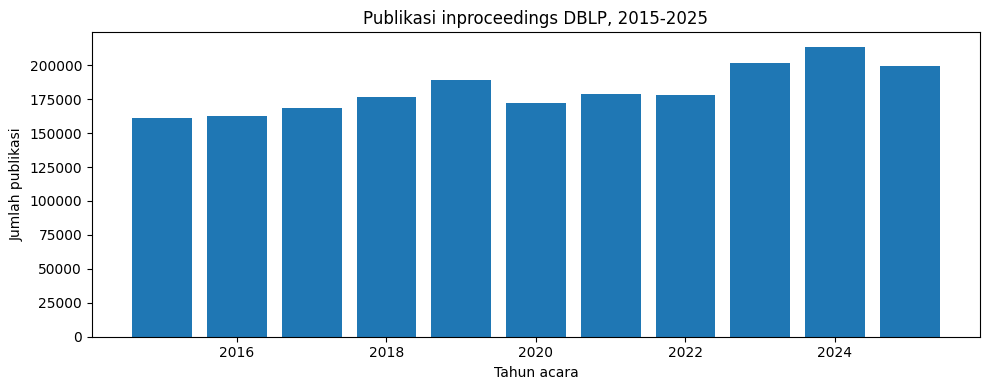

In [ ]:
by_year = pd.read_sql_query("SELECT year, COUNT(*) AS publications FROM publications GROUP BY year ORDER BY year", con)
by_year.to_csv(RESULTS / "task1_by_year.csv", index=False)
display(by_year)
fig, ax = plt.subplots(figsize=(10, 4))
ax.bar(by_year.year, by_year.publications)
ax.set(xlabel="Tahun acara", ylabel="Jumlah publikasi", title="Publikasi inproceedings DBLP, 2015-2025")
plt.tight_layout()
plt.show()

### Distribusi publikasi berdasarkan conference
Jumlah publikasi pada setiap venue, ditampilkan 20 venue teratas.

,venue,publications
0,NeurIPS,25004
1,ICASSP,21125
2,IGARSS,19685
3,AAAI,18406
4,CVPR,17435
5,EMBC,14677
6,ICML,13617
7,IROS,12832
8,ICRA,12361
9,CDC,11666


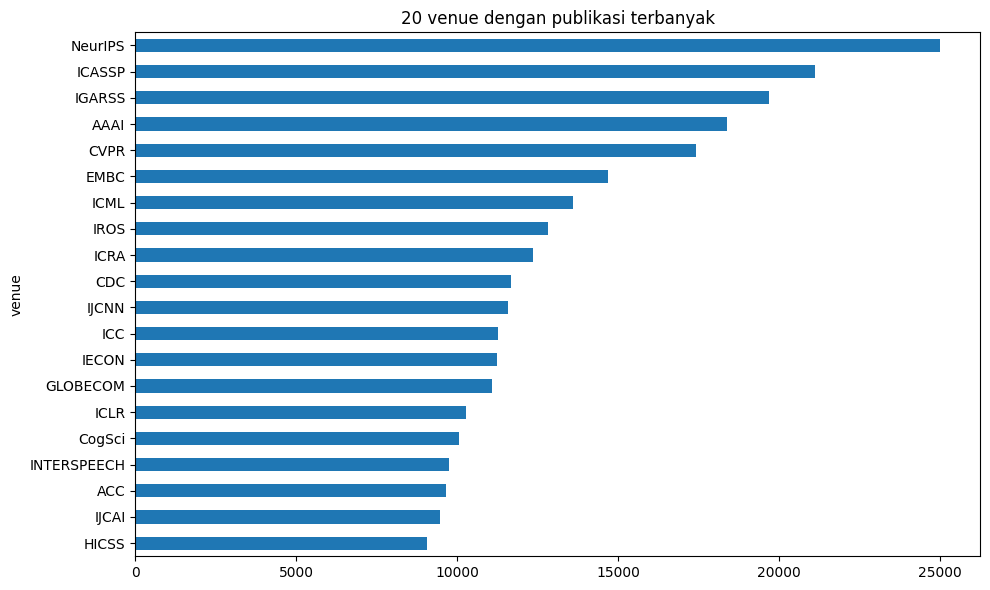

In [ ]:
by_venue = pd.read_sql_query("SELECT venue, COUNT(*) AS publications FROM publications GROUP BY venue ORDER BY publications DESC, venue", con)
by_venue.to_csv(RESULTS / "task1_by_venue.csv", index=False)
display(by_venue.head(20))
fig, ax = plt.subplots(figsize=(10, 6))
by_venue.head(20).iloc[::-1].plot.barh(x="venue", y="publications", ax=ax, legend=False, title="20 venue dengan publikasi terbanyak")
plt.tight_layout()
plt.show()

# Task 2 - Conference Popularity Analysis
Popularitas konferensi diukur dari aktivitas publikasi, memakai nama venue hasil normalisasi di Task 1 (NIPS sudah menjadi NeurIPS).

## 1. 10 konferensi dengan jumlah publikasi terbanyak
Jumlah publikasi dihitung per venue.

,venue,publications
0,NeurIPS,25004
1,ICASSP,21125
2,IGARSS,19685
3,AAAI,18406
4,CVPR,17435
5,EMBC,14677
6,ICML,13617
7,IROS,12832
8,ICRA,12361
9,CDC,11666


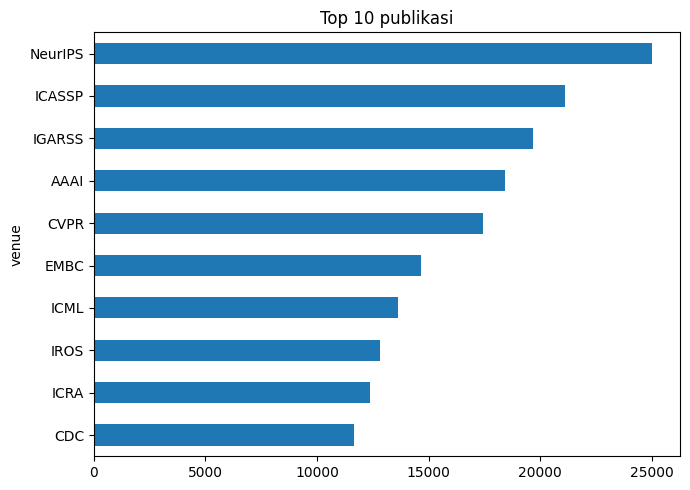

In [ ]:
publications_by_venue = pd.read_sql_query("""
SELECT venue, COUNT(*) AS publications FROM publications
GROUP BY venue ORDER BY publications DESC, venue
""", con)
top_pubs = publications_by_venue.head(10)
top_pubs.to_csv(RESULTS / "task2_top_publications.csv", index=False)
display(top_pubs)
top_pubs.iloc[::-1].plot.barh(x="venue", y="publications", legend=False, title="Top 10 publikasi", figsize=(7, 5))
plt.tight_layout()
plt.show()

## 2. 10 konferensi dengan jumlah author unik terbanyak
Author unik dihitung per venue setelah join publikasi dan authorship, sehingga author dengan beberapa paper di venue yang sama dihitung sekali.

,venue,unique_authors
0,NeurIPS,56068
1,AAAI,44594
2,ICASSP,41095
3,EMBC,39318
4,IGARSS,35230
5,CVPR,34964
6,ICML,31394
7,IROS,31198
8,IJCNN,29802
9,ICLR,28751


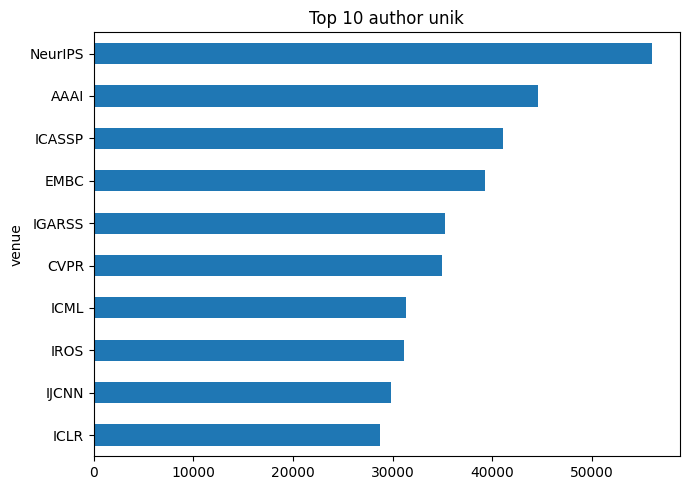

In [ ]:
authors_by_venue = pd.read_sql_query("""
SELECT p.venue AS venue, COUNT(DISTINCT a.author) AS unique_authors
FROM publications p JOIN authorship a USING (dblp_key)
GROUP BY p.venue ORDER BY unique_authors DESC, venue
""", con)
top_authors = authors_by_venue.head(10)
top_authors.to_csv(RESULTS / "task2_top_authors.csv", index=False)
display(top_authors)
top_authors.iloc[::-1].plot.barh(x="venue", y="unique_authors", legend=False, title="Top 10 author unik", figsize=(7, 5))
plt.tight_layout()
plt.show()

## 3. Tren jumlah publikasi berdasarkan tahun 2015-2025
Jumlah publikasi per tahun untuk venue yang masuk lima besar pada salah satu ranking di atas.

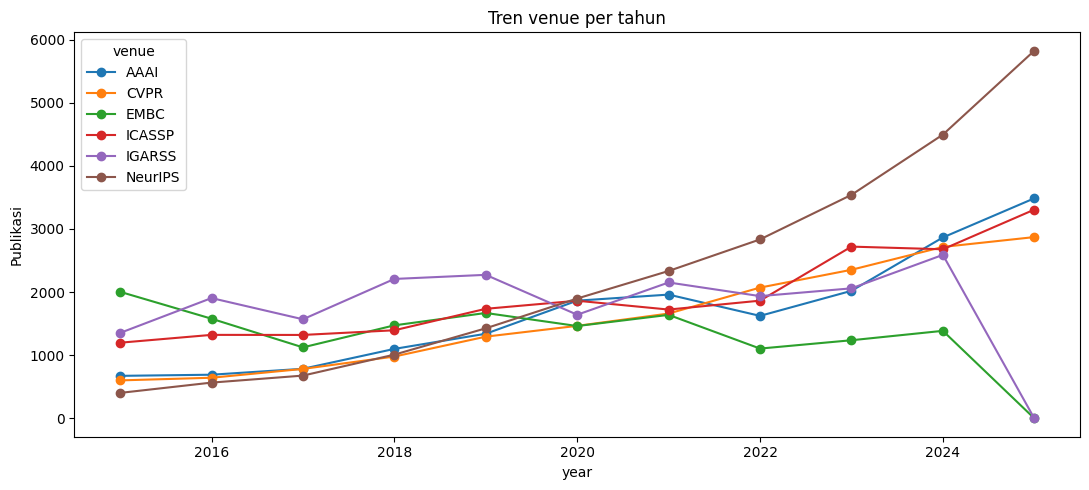

In [ ]:
leaders = tuple(dict.fromkeys(top_pubs.venue.head(5).tolist() + top_authors.venue.head(5).tolist()))
trend = pd.read_sql_query("SELECT year, venue, COUNT(*) AS publications FROM publications GROUP BY year, venue", con)
trend.to_csv(RESULTS / "task2_trend_all_venues.csv", index=False)
trend_pivot = trend[trend.venue.isin(leaders)].pivot(index="year", columns="venue", values="publications").fillna(0)
trend_pivot.plot(figsize=(11, 5), marker="o", title="Tren venue per tahun")
plt.ylabel("Publikasi")
plt.tight_layout()
plt.show()

## 4. Perbandingan ranking publikasi dan author unik
Menggabungkan kedua ranking. `rank_difference` bernilai positif jika venue lebih tinggi pada ranking author unik daripada ranking publikasi.

In [ ]:
ranking = publications_by_venue.merge(authors_by_venue, on="venue", how="outer")
ranking["rank_publications"] = ranking["publications"].rank(ascending=False, method="min").astype(int)
ranking["rank_unique_authors"] = ranking["unique_authors"].rank(ascending=False, method="min").astype(int)
ranking["rank_difference"] = ranking["rank_publications"] - ranking["rank_unique_authors"]
in_top10 = ranking[(ranking["rank_publications"] <= 10) | (ranking["rank_unique_authors"] <= 10)]
overlap = len(set(top_pubs.venue) & set(top_authors.venue))
print(f"Venue yang masuk 10 besar pada kedua ranking: {overlap} dari 10")
in_top10.sort_values("rank_publications")

Venue yang masuk 10 besar pada kedua ranking: 8 dari 10


,venue,publications,unique_authors,rank_publications,rank_unique_authors,rank_difference
6462,NeurIPS,25004,56068,1,1,0
3845,ICASSP,21125,41095,2,3,-1
4704,IGARSS,19685,35230,3,5,-2
50,AAAI,18406,44594,4,2,2
1816,CVPR,17435,34964,5,6,-1
2653,EMBC,14677,39318,6,4,2
4328,ICML,13617,31394,7,7,0
4928,IROS,12832,31198,8,8,0
4469,ICRA,12361,28542,9,11,-2
1288,CDC,11666,14393,10,35,-25


## 5. Hasil analisis
1. Konferensi paling populer berdasarkan jumlah publikasi
NeurIPS paling populer dengan 25.004 publikasi selama 2015-2025 (gabungan nama NIPS dan NeurIPS).
Berikutnya ICASSP (21.125), IGARSS (19.685), AAAI (18.406), dan CVPR (17.435).
Popularitas diukur dari volume publikasi, bukan mutu atau prestise konferensi.

2. Apakah konferensi dengan publikasi terbanyak juga punya author unik terbanyak?
Untuk posisi pertama, ya: NeurIPS juga teratas pada author unik (56.068).
Untuk keseluruhan 10 besar, tidak sepenuhnya: hanya 8 dari 10 venue muncul di kedua ranking.
ICRA dan CDC masuk 10 besar publikasi tetapi tidak masuk 10 besar author unik, sedangkan IJCNN dan ICLR sebaliknya.
CDC paling mencolok: peringkat 10 menurut publikasi tetapi peringkat 35 menurut author unik (14.393), artinya paper-nya banyak ditulis oleh kelompok author yang sama berulang (sekitar 1,2 author unik per paper, dibanding 2,2 pada NeurIPS).
Urutan juga bergeser: AAAI peringkat 4 menurut publikasi tetapi peringkat 2 menurut author unik, sedangkan IGARSS peringkat 3 menurut publikasi tetapi peringkat 5.
Jadi jumlah paper dan luas partisipasi author berkaitan, tetapi tidak menghasilkan urutan yang sama.

3. Perubahan aktivitas publikasi selama periode pengamatan
Jumlah publikasi per tahun secara umum naik, dari 161.346 (2015) menjadi 213.568 (2024), dengan penurunan sementara pada 2020 (172.091 dari 188.804 pada 2019).
Kenaikan terbesar ada pada venue AI dan machine learning: NeurIPS naik dari 403 (2015) menjadi 5.823 (2025), CVPR dari 601 menjadi 2.871, dan AAAI dari 673 menjadi 3.485.
Venue lain berubah-ubah: AAAI sempat turun pada 2022 (1.623 dari 1.960 pada 2021) sebelum naik lagi, dan EMBC cenderung turun dari 2.004 (2015) menjadi 1.386 (2024).
Data 2025 belum lengkap: IGARSS dan EMBC tidak punya record 2025 pada snapshot ini.
Angka nol itu berarti prosiding 2025 mereka belum terindeks di DBLP saat data diambil, dan tidak berarti konferensinya berhenti.

# Task 3 - Transactional Database Construction
Setiap item adalah nama venue. Transaksi disimpan sebagai himpunan sehingga paper berulang di venue yang sama tidak menggandakan item, dan transaksi satu item tetap dihitung pada penyebut support.

## 1. Membentuk transactional database

### Author-based transaction
Setiap transaksi adalah satu author, itemnya adalah semua venue tempat author itu pernah publikasi selama 2015-2025.

In [ ]:
author_venue = pd.read_sql_query("""
SELECT DISTINCT a.author, p.venue FROM authorship a JOIN publications p USING (dblp_key)
ORDER BY a.author, p.venue
""", con)
author_tx = author_venue.groupby("author", sort=False).venue.agg(lambda s: tuple(sorted(set(s)))).reset_index(name="items")
del author_venue
author_tx.to_pickle(OUT / "author_transactions.pkl")
print("Transaksi author-based:", f"{len(author_tx):,}")

Transaksi author-based: 1,822,238


### Author-year-based transaction
Setiap transaksi adalah satu kombinasi author dan tahun, itemnya adalah venue tempat author itu publikasi pada tahun tersebut.

In [ ]:
author_year_venue = pd.read_sql_query("""
SELECT DISTINCT a.author, p.year, p.venue FROM authorship a JOIN publications p USING (dblp_key)
ORDER BY a.author, p.year, p.venue
""", con)
author_year_tx = author_year_venue.groupby(["author", "year"], sort=False).venue.agg(lambda s: tuple(sorted(set(s)))).reset_index(name="items")
del author_year_venue
author_year_tx.to_pickle(OUT / "author_year_transactions.pkl")
print("Transaksi author-year-based:", f"{len(author_year_tx):,}")

Transaksi author-year-based: 4,088,191


## 2. Contoh transaksi
Sepuluh transaksi yang diambil acak (`random_state=42`) dari masing-masing representasi.

### Author-based transaction

In [ ]:
author_tx.sample(10, random_state=42)

,author,items
1041175,Michael François,"(IGARSS,)"
1532256,Thanh-Lam Nguyen,"(ICGEC (1),)"
1590017,Valtteri Lipiäinen,"(ISCC,)"
617643,Ian Baring-Gould,"(GHTC,)"
1511340,Takahiro Nomiyama,"(A-SSCC, ISSCC, VLSI Technology and Circuits)"
343240,David Söderman,"(ICMLA,)"
542784,Haihang Zhou,"(ICDE, INFOCOM, SMARTCOMP)"
1261931,Rabah Benkercha,"(ICMLA,)"
1461456,Sonny Wainalang,"(IOTAIS,)"
1111095,Nadia Abchiche-Mimouni,"(AAMAS, CAL, EXTRAAMAS@AAMAS, FIE, ICAART (3),..."


### Author-year-based transaction

In [ ]:
author_year_tx.sample(10, random_state=42)

,author,year,items
2663404,Pearse A. Keane,2017,"(ICCV,)"
1670294,Josefine Engel,2016,"(SOUPS,)"
578808,Ching-Ting Wang,2023,"(SmartCloud,)"
1200562,Hamed Hosseiny,2016,"(PIMRC,)"
2500877,Neha M. Jadhav,2020,"(W4A,)"
2596127,Omid Rezayof,2025,"(ICRA, IROS)"
910444,Enrique Vallejo 0002,2025,"(CBMS,)"
51676,Adrià Giménez-Pastor,2021,"(Interspeech,)"
2613683,Pablo F. Castro,2016,"(ASE, SBMF)"
1723385,Jun Kuribayashi,2025,"(CHI, CHI Extended Abstracts)"


## 3. Jumlah transaksi
Jumlah transaksi pada masing-masing transactional database.

In [ ]:
pd.Series({"Author-based": len(author_tx), "Author-year-based": len(author_year_tx)}).to_frame("transaksi")

,transaksi
Author-based,1822238
Author-year-based,4088191


## 4. Item unik dan distribusi item per transaksi

### Jumlah item unik
Jumlah venue berbeda yang muncul sebagai item pada masing-masing representasi.

In [ ]:
pd.Series({
    "Author-based": len({x for row in author_tx["items"] for x in row}),
    "Author-year-based": len({x for row in author_year_tx["items"] for x in row}),
}).to_frame("item unik")

,item unik
Author-based,8902
Author-year-based,8902


### Distribusi jumlah item per transaksi
Statistik jumlah item per transaksi dan histogramnya, dengan transaksi berisi 20 item atau lebih digabung pada satu batang.

,Author-based,Author-year-based
count,1.822238e+06,4.088191e+06
mean,2.862256e+00,1.627094e+00
std,5.099109e+00,1.489288e+00
min,1.000000e+00,1.000000e+00
25%,1.000000e+00,1.000000e+00
50%,1.000000e+00,1.000000e+00
75%,3.000000e+00,2.000000e+00
max,3.980000e+02,8.900000e+01


,Author-based,Author-year-based
porsi transaksi satu item,0.574022,0.702798


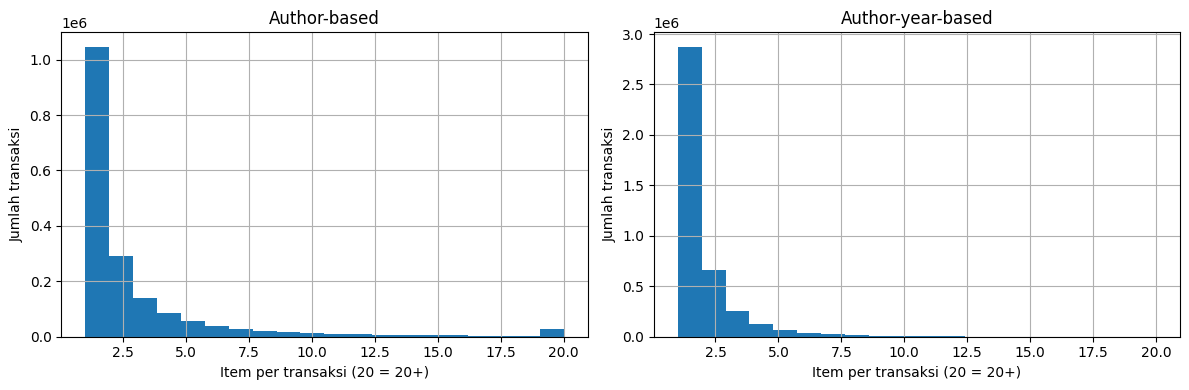

In [ ]:
sizes = {"Author-based": author_tx["items"].map(len), "Author-year-based": author_year_tx["items"].map(len)}
display(pd.DataFrame({name: s.describe() for name, s in sizes.items()}))
display(pd.DataFrame({name: (s == 1).mean() for name, s in sizes.items()}, index=["porsi transaksi satu item"]))
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
for ax, (name, s) in zip(axes, sizes.items()):
    s.clip(upper=20).hist(ax=ax, bins=20)
    ax.set(xlabel="Item per transaksi (20 = 20+)", ylabel="Jumlah transaksi", title=name)
plt.tight_layout()
plt.show()

## 5. Analisis perbedaan Author-Based vs Author-Year-Based
Perbedaan utama ada pada jumlah dan panjang transaksi.
Author-based menghasilkan 1.822.238 transaksi, sedangkan Author-year-based menghasilkan 4.088.191 transaksi (2,24 kali lebih banyak) karena satu author dipecah menjadi satu transaksi per tahun ia aktif.
Jumlah item unik sama (8.902 venue), tetapi transaksi Author-based lebih panjang: rata-rata 2,86 item (maksimum 398) dibanding 1,63 item (maksimum 89) pada Author-year-based.
Porsi transaksi satu item juga berbeda, 57,4% pada Author-based dan 70,3% pada Author-year-based, padahal transaksi satu item tidak menghasilkan pasangan venue apa pun.
Artinya Author-based menangkap semua venue yang pernah dipakai seorang author selama 11 tahun, sedangkan Author-year-based hanya menangkap venue yang dipakai pada tahun yang sama.

## 6. Kelebihan dan keterbatasan masing-masing representasi untuk Frequent Pattern Mining
Author-based
- Kelebihan: transaksi lebih panjang dan transaksi satu itemnya lebih sedikit, sehingga lebih banyak kombinasi venue yang bisa ditemukan (pada support 0,1% ditemukan 1.193 frequent itemset). Cocok untuk melihat komunitas venue secara umum.
- Keterbatasan: menggabungkan 11 tahun, sehingga dua venue bisa terlihat berpasangan padahal author berpindah bidang dari satu tahun ke tahun lain. Tidak bisa dipakai untuk melihat perubahan antarperiode. Author produktif dengan puluhan venue (maksimum 398) menyumbang banyak pasangan dan dapat mendominasi pola.

Author-year-based
- Kelebihan: hanya menghitung venue yang dipakai pada tahun yang sama, sehingga pola lebih menggambarkan kegiatan yang berjalan bersamaan, dan transaksinya bisa dibagi per periode untuk analisis temporal (Bagian E).
- Keterbatasan: transaksi lebih pendek (70,3% hanya satu item), sehingga support kombinasi venue lebih kecil dan lebih sedikit pola yang melewati minimum support. Author yang aktif beberapa tahun terhitung berkali-kali, sehingga lebih berpengaruh daripada author yang hanya muncul sekali.

# Task 4 - Frequent Pattern Mining
Apriori dan FP-Growth diimplementasikan sendiri (tanpa library mining) dan dijalankan pada transaksi Author-Based dengan empat nilai minimum support. Keduanya memakai input dan format hasil yang sama, sehingga bisa dibandingkan langsung di Task 6.

## 1. Implementasi Apriori dan FP-Growth

### Transaksi terkode
Mengubah nama venue menjadi nomor item dan menyimpan transaksi yang identik satu kali beserta jumlah kemunculannya. Kedua algoritma jadi membaca jauh lebih sedikit baris, sementara support count tetap tepat.

In [ ]:
@dataclass
class TransactionDB:
    weighted: dict
    n_transactions: int
    items: list

    def min_count(self, min_support):
        return max(1, math.ceil(min_support * self.n_transactions - 1e-9))


def encode_transactions(item_tuples):
    occurrences = item_tuples.value_counts()
    items = sorted({item for transaction in occurrences.index for item in transaction})
    item_id = {item: i for i, item in enumerate(items)}
    weighted = {tuple(sorted(item_id[item] for item in transaction)): int(count)
                for transaction, count in occurrences.items()}
    return TransactionDB(weighted, int(occurrences.sum()), items)


author_db = encode_transactions(author_tx["items"])
print(f"Transaksi: {author_db.n_transactions:,} | transaksi berbeda: {len(author_db.weighted):,} | item: {len(author_db.items):,}")

Transaksi: 1,822,238 | transaksi berbeda: 618,049 | item: 8,902


### Apriori
Apriori bekerja per level. Kandidat k-itemset dibentuk dari frequent (k-1)-itemset yang berbagi k-2 item pertama, kandidat yang punya subset tidak frequent dibuang (sifat Apriori), lalu satu pemindaian data menghitung support kandidat yang tersisa.

In [ ]:
def generate_candidates(frequent, k):
    by_prefix = defaultdict(list)
    for itemset in frequent:
        by_prefix[itemset[:-1]].append(itemset[-1])
    candidates = set()
    for prefix, last_items in by_prefix.items():
        last_items.sort()
        for a, b in combinations(last_items, 2):
            candidate = prefix + (a, b)
            if all(subset in frequent for subset in combinations(candidate, k - 1)):
                candidates.add(candidate)
    return candidates


def count_candidates(transactions, candidates, k):
    counts = dict.fromkeys(candidates, 0)
    for transaction, weight in transactions.items():
        if math.comb(len(transaction), k) <= len(candidates):
            for subset in combinations(transaction, k):
                if subset in counts:
                    counts[subset] += weight
        else:
            items = set(transaction)
            for candidate in candidates:
                if items.issuperset(candidate):
                    counts[candidate] += weight
    return counts


def reduce_transactions(transactions, keep, min_length):
    reduced = Counter()
    for transaction, weight in transactions.items():
        kept = tuple(item for item in transaction if item in keep)
        if len(kept) >= min_length:
            reduced[kept] += weight
    return reduced


def apriori(db, min_support):
    min_count = db.min_count(min_support)
    item_counts = Counter()
    for transaction, weight in db.weighted.items():
        for item in transaction:
            item_counts[item] += weight
    frequent = {(item,): count for item, count in item_counts.items() if count >= min_count}
    result = dict(frequent)
    transactions = db.weighted
    k = 2
    while frequent:
        candidates = generate_candidates(set(frequent), k)
        if not candidates:
            break
        candidate_items = {item for candidate in candidates for item in candidate}
        transactions = reduce_transactions(transactions, candidate_items, k)
        counts = count_candidates(transactions, candidates, k)
        frequent = {itemset: count for itemset, count in counts.items() if count >= min_count}
        result.update(frequent)
        k += 1
    return result


print("Apriori siap, hasil berupa {itemset: support count}")

Apriori siap, hasil berupa {itemset: support count}


### FP-Growth
FP-Growth membaca data dua kali (menghitung item, lalu menyusun FP-tree) dan tidak membuat kandidat. Pola dikembangkan langsung dari pohon, dengan conditional FP-tree yang dibangun dari jalur menuju tiap item.

In [ ]:
class Node:
    __slots__ = ("item", "count", "parent", "children", "link")

    def __init__(self, item, parent):
        self.item = item
        self.count = 0
        self.parent = parent
        self.children = {}
        self.link = None


def build_tree(transactions, min_count):
    transactions = list(transactions)
    item_counts = Counter()
    for items, weight in transactions:
        for item in items:
            item_counts[item] += weight
    item_counts = {item: count for item, count in item_counts.items() if count >= min_count}
    root = Node(None, None)
    header = {}
    for items, weight in transactions:
        ordered = sorted((item for item in items if item in item_counts), key=lambda item: (-item_counts[item], item))
        node = root
        for item in ordered:
            child = node.children.get(item)
            if child is None:
                child = Node(item, node)
                node.children[item] = child
                child.link = header.get(item)
                header[item] = child
            child.count += weight
            node = child
    return header, item_counts


def mine_tree(header, item_counts, suffix, min_count, result):
    for item in sorted(item_counts, key=lambda item: (item_counts[item], item)):
        pattern = suffix + (item,)
        result[tuple(sorted(pattern))] = item_counts[item]
        conditional_base = []
        node = header[item]
        while node is not None:
            path = []
            parent = node.parent
            while parent.item is not None:
                path.append(parent.item)
                parent = parent.parent
            if path:
                conditional_base.append((path, node.count))
            node = node.link
        if conditional_base:
            cond_header, cond_counts = build_tree(conditional_base, min_count)
            if cond_counts:
                mine_tree(cond_header, cond_counts, pattern, min_count, result)


def fpgrowth(db, min_support):
    min_count = db.min_count(min_support)
    header, item_counts = build_tree(db.weighted.items(), min_count)
    result = {}
    mine_tree(header, item_counts, (), min_count, result)
    return result


print("FP-Growth siap, hasil berupa {itemset: support count}")

FP-Growth siap, hasil berupa {itemset: support count}


### Fungsi eksperimen
Mengubah hasil algoritma menjadi tabel (itemset, length, support_count, support) dan menjalankan satu algoritma pada satu minimum support. Waktu yang dicatat adalah median dari beberapa kali jalan dan hanya mencakup waktu mining. `run_experiment` menjalankan kedua algoritma pada satu support dan memeriksa hasilnya sama.

In [ ]:
mining = {}


def itemsets_to_frame(itemsets, db):
    frame = pd.DataFrame({
        "itemset": [tuple(sorted(db.items[item] for item in itemset)) for itemset in itemsets],
        "length": [len(itemset) for itemset in itemsets],
        "support_count": list(itemsets.values()),
    })
    frame["support"] = frame["support_count"] / db.n_transactions
    return frame.sort_values(["support_count", "itemset"], ascending=[False, True]).reset_index(drop=True)


def mine(db, algorithm, min_support, repeats=1):
    algorithms = {"Apriori": apriori, "FP-Growth": fpgrowth}
    runtimes = []
    for _ in range(repeats):
        start = time.perf_counter()
        raw_itemsets = algorithms[algorithm](db, min_support)
        runtimes.append(time.perf_counter() - start)
    return itemsets_to_frame(raw_itemsets, db), statistics.median(runtimes)


def join_items(frame, columns):
    return frame.assign(**{column: frame[column].str.join(" | ") for column in columns})


def run_experiment(support):
    for algorithm in ("Apriori", "FP-Growth"):
        found, seconds = mine(author_db, algorithm, support, RUNTIME_REPEATS)
        mining[(algorithm, support)] = {"itemsets": found, "seconds": seconds}
        join_items(found, ["itemset"]).to_csv(RESULTS / f"task4_{algorithm.lower().replace('-', '')}_{support}.csv", index=False)
        print(f"{algorithm} support={support:.1%}: {len(found):,} itemset, {seconds:.2f} detik (median {RUNTIME_REPEATS} kali)")
    a, f = mining[("Apriori", support)]["itemsets"], mining[("FP-Growth", support)]["itemsets"]
    print("Itemset dan support count Apriori dan FP-Growth sama:", dict(zip(a.itemset, a.support_count)) == dict(zip(f.itemset, f.support_count)))


def mining_summary_table():
    rows = []
    for (algorithm, support), result in mining.items():
        found = result["itemsets"]
        lengths = found["length"].value_counts()
        rows.append({"algorithm": algorithm, "min_support": support, "seconds": result["seconds"],
                     "itemsets": len(found), "max_length": int(found["length"].max()) if len(found) else 0,
                     **{f"{k}-itemsets": int(lengths.get(k, 0)) for k in (1, 2, 3)}})
    return pd.DataFrame(rows).sort_values(["min_support", "algorithm"]).reset_index(drop=True)

## 2. Frequent itemsets untuk setiap minimum support
Setiap sel menjalankan Apriori dan FP-Growth pada satu minimum support.

### Minimum support 0,1%

In [ ]:
run_experiment(0.001)

Apriori support=0.1%: 1,193 itemset, 4.91 detik (median 3 kali)
FP-Growth support=0.1%: 1,193 itemset, 9.44 detik (median 3 kali)
Itemset dan support count Apriori dan FP-Growth sama: True


### Minimum support 0,5%

In [ ]:
run_experiment(0.005)

Apriori support=0.5%: 75 itemset, 1.16 detik (median 3 kali)
FP-Growth support=0.5%: 75 itemset, 2.61 detik (median 3 kali)
Itemset dan support count Apriori dan FP-Growth sama: True


### Minimum support 1%

In [ ]:
run_experiment(0.01)

Apriori support=1.0%: 25 itemset, 0.98 detik (median 3 kali)
FP-Growth support=1.0%: 25 itemset, 1.54 detik (median 3 kali)
Itemset dan support count Apriori dan FP-Growth sama: True


### Minimum support 2%

In [ ]:
run_experiment(0.02)

Apriori support=2.0%: 4 itemset, 0.76 detik (median 3 kali)
FP-Growth support=2.0%: 4 itemset, 1.25 detik (median 3 kali)
Itemset dan support count Apriori dan FP-Growth sama: True


## 3. Frequent 1-itemsets, 2-itemsets, dan 3-itemsets
Jumlah frequent itemset menurut ukurannya pada setiap minimum support.

In [ ]:
mining_summary = mining_summary_table()
mining_summary.to_csv(RESULTS / "task4_summary.csv", index=False)
mining_summary[["algorithm", "min_support", "itemsets", "1-itemsets", "2-itemsets", "3-itemsets", "max_length"]]

,algorithm,min_support,itemsets,1-itemsets,2-itemsets,3-itemsets,max_length
0,Apriori,0.001,1193,535,328,237,5
1,FP-Growth,0.001,1193,535,328,237,5
2,Apriori,0.005,75,63,11,1,3
3,FP-Growth,0.005,75,63,11,1,3
4,Apriori,0.010,25,24,1,0,2
5,FP-Growth,0.010,25,24,1,0,2
6,Apriori,0.020,4,4,0,0,1
7,FP-Growth,0.020,4,4,0,0,1


## 4. 10 frequent itemsets dengan support tertinggi
Itemset diambil dari hasil FP-Growth, yang identik dengan hasil Apriori. Kolom `support_count` adalah jumlah author yang memuat itemset tersebut.

In [ ]:
def top_itemsets(support, n=10, min_length=1):
    found = mining[("FP-Growth", support)]["itemsets"]
    return join_items(found[found["length"] >= min_length].head(n).reset_index(drop=True), ["itemset"])

### Minimum support 0,1%

In [ ]:
top_itemsets(0.001)

,itemset,length,support_count,support
0,NeurIPS,1,56068,0.030769
1,AAAI,1,44594,0.024472
2,ICASSP,1,41095,0.022552
3,EMBC,1,39318,0.021577
4,IGARSS,1,35230,0.019333
5,CVPR,1,34964,0.019187
6,ICML,1,31394,0.017228
7,IROS,1,31198,0.017121
8,IJCNN,1,29802,0.016355
9,ICLR,1,28751,0.015778


### Minimum support 0,5%

In [ ]:
top_itemsets(0.005)

,itemset,length,support_count,support
0,NeurIPS,1,56068,0.030769
1,AAAI,1,44594,0.024472
2,ICASSP,1,41095,0.022552
3,EMBC,1,39318,0.021577
4,IGARSS,1,35230,0.019333
5,CVPR,1,34964,0.019187
6,ICML,1,31394,0.017228
7,IROS,1,31198,0.017121
8,IJCNN,1,29802,0.016355
9,ICLR,1,28751,0.015778


### Minimum support 1%

In [ ]:
top_itemsets(0.01)

,itemset,length,support_count,support
0,NeurIPS,1,56068,0.030769
1,AAAI,1,44594,0.024472
2,ICASSP,1,41095,0.022552
3,EMBC,1,39318,0.021577
4,IGARSS,1,35230,0.019333
5,CVPR,1,34964,0.019187
6,ICML,1,31394,0.017228
7,IROS,1,31198,0.017121
8,IJCNN,1,29802,0.016355
9,ICLR,1,28751,0.015778


### Minimum support 2%

In [ ]:
top_itemsets(0.02)

,itemset,length,support_count,support
0,NeurIPS,1,56068,0.030769
1,AAAI,1,44594,0.024472
2,ICASSP,1,41095,0.022552
3,EMBC,1,39318,0.021577


## 5. Pengaruh minimum support terhadap jumlah frequent itemsets
Jumlah frequent itemset pada setiap minimum support, dengan skala log pada sumbu jumlah.

,itemsets,1-itemsets,2-itemsets,3-itemsets,max_length
min_support,,,,,
0.001,1193,535,328,237,5
0.005,75,63,11,1,3
0.010,25,24,1,0,2
0.020,4,4,0,0,1


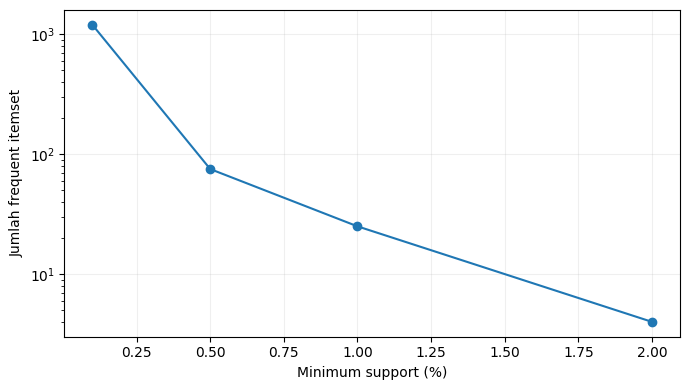

In [ ]:
influence = mining_summary[mining_summary["algorithm"] == "FP-Growth"].set_index("min_support")[["itemsets", "1-itemsets", "2-itemsets", "3-itemsets", "max_length"]]
display(influence)
fig, ax = plt.subplots(figsize=(7, 4))
ax.plot(influence.index * 100, influence["itemsets"], marker="o")
ax.set(xlabel="Minimum support (%)", ylabel="Jumlah frequent itemset", yscale="log")
ax.grid(alpha=.2)
plt.tight_layout()
plt.show()

## 6. Kombinasi conference yang paling sering muncul bersama
Sepuluh itemset berisi dua venue atau lebih dengan support tertinggi, diambil dari hasil minimum support 0,1% karena mencakup semua itemset yang lolos pada support yang lebih tinggi.

In [ ]:
top_itemsets(0.001, min_length=2)

,itemset,length,support_count,support
0,ICML | NeurIPS,2,18241,0.010010
1,ICLR | NeurIPS,2,16885,0.009266
2,AAAI | NeurIPS,2,15555,0.008536
3,CVPR | NeurIPS,2,14008,0.007687
4,CVPR | ICCV,2,13590,0.007458
5,ICLR | ICML,2,12286,0.006742
6,ICRA | IROS,2,11859,0.006508
7,AAAI | IJCAI,2,11013,0.006044
8,AAAI | CVPR,2,10860,0.005960
9,ICCV | NeurIPS,2,10440,0.005729


## 7. Hasil Frequent Patterns
Pengaruh minimum support: semakin rendah minimum support, semakin banyak frequent itemset dan semakin panjang itemset yang ditemukan.
Pada 0,1% ditemukan 1.193 itemset (535 satu item, 328 dua item, 237 tiga item, 85 empat item, dan 8 lima item), pada 0,5% tinggal 75 (panjang maksimum 3), pada 1% tinggal 25 (hanya satu pasangan), dan pada 2% hanya 4 itemset yang semuanya venue tunggal: NeurIPS, AAAI, ICASSP, dan EMBC.
Penurunannya tajam karena kebanyakan venue kecil: dari 8.902 venue, hanya 535 yang dipakai oleh minimal 0,1% author.

Itemset dengan support tertinggi selalu venue tunggal, karena support sebuah kombinasi tidak mungkin lebih besar daripada support venue penyusunnya.
NeurIPS teratas, dipakai 56.068 author (3,08%), diikuti AAAI (44.594), ICASSP (41.095), EMBC (39.318), dan IGARSS (35.230).

Kombinasi venue yang paling sering muncul bersama adalah ICML + NeurIPS (18.241 author, 1,00%), ICLR + NeurIPS (16.885), AAAI + NeurIPS (15.555), CVPR + NeurIPS (14.008), dan CVPR + ICCV (13.590).
Kombinasi tiga venue terbesar adalah ICLR + ICML + NeurIPS (9.926 author), dan itemset terbesar (empat sampai lima venue, misalnya AAAI + ICLR + ICML + NeurIPS pada 4.684 author) juga terdiri dari venue AI.
NeurIPS menjadi penghubung bagi ICML, ICLR, AAAI, CVPR, dan ICCV. Di luar kelompok itu, pasangan yang menonjol adalah ICRA + IROS (11.859 author, robotika) dan AAAI + IJCAI (11.013).
Pola ini menunjukkan tumpang tindih author di antara venue yang berdekatan bidangnya, dan tidak menunjukkan hubungan sebab-akibat.

# Task 5 - Association Rule Mining
Rule dibangkitkan dari frequent itemsets FP-Growth dengan minimum confidence 50%. Lift adalah confidence dibagi support consequent, lift di atas 1 berarti kedua sisi muncul bersama lebih sering daripada perkiraan jika keduanya independen.

## 1. Membangkitkan association rules

### Fungsi pembangkit rule
Untuk setiap frequent itemset I dan setiap pembagian menjadi antecedent A dan consequent B, support = count(I) / N, confidence = count(I) / count(A), dan lift = confidence / support(B). Semua subset dari itemset yang frequent juga frequent, sehingga count(A) dan count(B) selalu tersedia.

In [ ]:
RULE_COLUMNS = ["antecedent", "consequent", "support", "confidence", "lift", "support_count", "antecedent_support", "consequent_support"]


def association_rules(itemsets, n_transactions, min_confidence=MIN_CONFIDENCE):
    counts = dict(zip(itemsets["itemset"], itemsets["support_count"]))
    rows = []
    for itemset, count in counts.items():
        if len(itemset) < 2:
            continue
        for size in range(1, len(itemset)):
            for antecedent in combinations(itemset, size):
                confidence = count / counts[antecedent]
                if confidence < min_confidence:
                    continue
                consequent = tuple(item for item in itemset if item not in antecedent)
                consequent_support = counts[consequent] / n_transactions
                rows.append((antecedent, consequent, count / n_transactions, confidence, confidence / consequent_support,
                             count, counts[antecedent] / n_transactions, consequent_support))
    rules = pd.DataFrame(rows, columns=RULE_COLUMNS)
    rules = rules.astype({column: float for column in RULE_COLUMNS[2:]}).astype({"support_count": int})
    return rules.sort_values(["lift", "confidence", "support"], ascending=False).reset_index(drop=True)


def format_rules(rules):
    return pd.DataFrame({
        "rule": rules["antecedent"].str.join(", ") + "  ->  " + rules["consequent"].str.join(", "),
        "support": rules["support"].round(5),
        "confidence": rules["confidence"].round(3),
        "lift": rules["lift"].round(2),
        "support_count": rules["support_count"],
    }).reset_index(drop=True)


def show_top_rules(support, n=10):
    rules = rules_by_support[support]
    if rules.empty:
        return f"Tidak ada rule pada minimum support {support:.1%}"
    return format_rules(rules.head(n))

### Rule untuk setiap minimum support
Membangkitkan rule dari hasil FP-Growth pada keempat minimum support dan menyimpannya ke `results/main/`.

In [ ]:
rules_by_support = {}
for support in SUPPORTS:
    rules = association_rules(mining[("FP-Growth", support)]["itemsets"], author_db.n_transactions)
    rules_by_support[support] = rules
    join_items(rules, ["antecedent", "consequent"]).to_csv(RESULTS / f"task5_rules_{support}.csv", index=False)
    print(f"support={support:.1%}: {len(rules):,} rules")

support=0.1%: 730 rules
support=0.5%: 6 rules
support=1.0%: 1 rules
support=2.0%: 0 rules


In [ ]:
def show_all_rules(support):
    rules = rules_by_support[support]
    if rules.empty:
        return f"Tidak ada rule pada minimum support {support:.1%}"
    table = pd.DataFrame({
        "antecedent": rules["antecedent"].str.join(", "),
        "consequent": rules["consequent"].str.join(", "),
        "support": rules["support"].round(5),
        "confidence": rules["confidence"].round(3),
        "lift": rules["lift"].round(2),
    }).reset_index(drop=True)
    with pd.option_context("display.max_rows", None):
        display(table)

## 2. Hasil association rules (support, confidence, dan lift)
Semua rule yang lolos minimum confidence 50% pada setiap minimum support, diurutkan menurut lift.
Antecedent, consequent, support, confidence, dan lift masing-masing punya kolom sendiri.


### Minimum support 0,1%

In [ ]:
show_all_rules(0.001)

### Minimum support 0,5%

In [ ]:
show_all_rules(0.005)

### Minimum support 1%

In [ ]:
show_all_rules(0.01)

### Minimum support 2%

In [ ]:
show_all_rules(0.02)

## 3. Identifikasi hubungan asosiasi antar-konferensi
Sepuluh rule dengan lift tertinggi pada setiap minimum support.


In [ ]:
for support in SUPPORTS:
    print(f"Minimum support {support:.1%}: 10 rule dengan lift tertinggi")
    display(show_top_rules(support))

Pada minimum support 0,1% ditemukan 730 rule, pada 0,5% ada 6 rule, pada 1% hanya 1 rule (ICML -> NeurIPS), dan pada 2% tidak ada rule.
Rule dengan lift tertinggi (sekitar 100 sampai 123) semuanya menghubungkan venue AI dan computer vision, misalnya ACM Multimedia + CVPR + NeurIPS -> AAAI + ICCV (lift 122,69, confidence 55,4%) dan ICCV + ICML + NeurIPS -> CVPR + ICLR (lift 122,20, confidence 56,5%).
Rule seperti ini sangat spesifik: support-nya hanya sekitar 0,1% (sekitar 2.000 author), jadi menggambarkan kelompok kecil author yang sangat aktif di banyak venue sekaligus.

Rule yang paling menarik pada support yang lebih tinggi:
- ICLR + ICML -> NeurIPS: confidence tertinggi (80,8%), artinya empat dari lima author yang publikasi di ICLR dan ICML juga publikasi di NeurIPS (lift 26,26, 9.926 author).
- ICCV -> CVPR: dua venue computer vision, confidence 56,4%, lift 29,37, 13.590 author.
- ICML -> NeurIPS: satu-satunya rule yang melewati support 1% (confidence 58,1%, lift 18,88, 18.241 author).
Semua rule memiliki lift di atas 16, jadi pasangan venue tersebut muncul bersama jauh lebih sering daripada kebetulan.
Lift setinggi itu juga dipengaruhi banyaknya author yang hanya punya satu venue (57,4% transaksi), yang membuat peluang kebetulan sangat kecil.


## 4. Analisis konferensi yang memiliki support tinggi selalu menghasilkan lift yang tinggi
Memeriksa hubungan support dan lift pada minimum support 0,1% (730 rule).
Korelasi Spearman dihitung antara support dan lift, dan tabel menampilkan 10 rule dengan antecedent support tertinggi.


In [ ]:
chosen = rules_by_support[0.001]
print("Jumlah rule pada minimum support 0,1%:", len(chosen))
print("Korelasi Spearman antecedent support vs lift:", round(chosen["antecedent_support"].corr(chosen["lift"], method="spearman"), 3))
print("Korelasi Spearman support vs lift:", round(chosen["support"].corr(chosen["lift"], method="spearman"), 3))
join_items(chosen.sort_values("antecedent_support", ascending=False).head(10), ["antecedent", "consequent"])[["antecedent", "consequent", "antecedent_support", "support", "confidence", "lift"]].reset_index(drop=True)

Tidak. Support yang tinggi tidak selalu menghasilkan lift yang tinggi.
Korelasi Spearman antara antecedent support dan lift adalah -0,085, dan antara support rule dan lift adalah -0,140, sehingga hampir tidak ada hubungan (cenderung sedikit negatif).
Contohnya ICML -> NeurIPS punya antecedent support tertinggi (1,72% author) dan support rule 1,00%, tetapi lift-nya hanya 18,88, jauh di bawah rule dengan lift lebih dari 100 yang antecedent-nya kombinasi tiga venue dengan support sekitar 0,1%.
Penyebabnya lift = confidence / support consequent. Kalau consequent-nya venue besar seperti NeurIPS (3,08% author), confidence yang tinggi tetap menghasilkan lift yang moderat, sedangkan kombinasi venue yang jarang dapat menghasilkan lift sangat tinggi walaupun support-nya kecil.
Karena itu support dan lift perlu dibaca bersama: support menunjukkan seberapa umum pola itu, dan lift menunjukkan seberapa kuat hubungannya dibanding kebetulan.


## 5. Interpretasi support, confidence, dan lift
Ketiganya mengukur hal yang berbeda. Contoh rule ICML -> NeurIPS pada data ini:
- Support (1,00%): 18.241 dari 1.822.238 author publikasi di ICML dan NeurIPS sekaligus. Support mengukur seberapa umum kombinasi itu di seluruh data, dan nilainya sama untuk kedua arah.
- Confidence (58,1%): dari 31.394 author ICML, 18.241 juga publikasi di NeurIPS. Confidence mengukur seberapa andal rule itu dan bergantung pada arah: NeurIPS -> ICML hanya 32,5% (18.241 dari 56.068 author NeurIPS), sehingga tidak lolos minimum confidence 50% dan tidak muncul sebagai rule.
- Lift (18,88): confidence dibagi support NeurIPS (3,08%). Lift membandingkan dengan keadaan kalau kedua venue tidak berhubungan: lift 1 berarti independen, di atas 1 berarti muncul bersama lebih sering daripada kebetulan, dan di bawah 1 berarti lebih jarang.
Support dan confidence tinggi belum tentu berarti hubungan kuat karena keduanya ikut naik saat venue-nya besar, sedangkan lift menyesuaikan ukuran venue.

## 6. Pola publikasi antar-konferensi
Pola yang dapat diidentifikasi dari rule:
- Venue AI dan machine learning saling berpasangan kuat: ICML, ICLR, AAAI, dan IJCAI muncul bersama NeurIPS, dan NeurIPS menjadi penghubung utama (ICLR + ICML -> NeurIPS dengan confidence 80,8%).
- Venue computer vision berpasangan: ICCV -> CVPR (56,4%), dan CVPR + NeurIPS -> ICCV (55,7%, lift 42,10) menghubungkan vision dengan kelompok AI.
- Venue NLP seperti ACL dan EMNLP juga berpasangan dengan NeurIPS tetapi lebih lemah (lift terendah sekitar 16,5).
- Kombinasi lebih dari dua venue juga umum: 374 dari 730 rule pada support 0,1% punya dua venue di antecedent, dan 300 rule punya tiga.
Jadi author yang aktif di satu konferensi AI cenderung aktif di beberapa konferensi AI lain, dan pola publikasinya mengelompok menurut bidang penelitian.
Rule ini menunjukkan tumpang tindih author, dan tidak menunjukkan hubungan sebab-akibat.
Keterbatasan: venue yang namanya terpecah per jilid (misalnya ECCV dan ACL) belum digabung, sehingga hubungan mereka tidak tampak sepenuhnya, dan beberapa rule memuat varian nama seperti "ACL (Findings)" dan "ACL (1)".


# Task 6 - Algorithm Performance Comparison
Apriori dan FP-Growth dinilai pada transaksi dan minimum support yang sama. Waktu hanya waktu mining, tidak termasuk pembuatan transaksi terkode, dan dipengaruhi kondisi mesin saat dijalankan.

## 1. Jumlah frequent itemsets
Jumlah frequent itemset per algoritma pada setiap minimum support.

In [ ]:
comparison = mining_summary_table()
comparison.pivot(index="min_support", columns="algorithm", values="itemsets")

algorithm,Apriori,FP-Growth
min_support,,
0.001,1193,1193
0.005,75,75
0.010,25,25
0.020,4,4


## 2. Jumlah association rules
Jumlah rule yang dihasilkan dari frequent itemsets masing-masing algoritma pada minimum confidence 50%.

In [ ]:
comparison["rules"] = comparison.apply(
    lambda row: len(association_rules(mining[(row["algorithm"], row["min_support"])]["itemsets"], author_db.n_transactions)), axis=1
)
comparison.pivot(index="min_support", columns="algorithm", values="rules")

algorithm,Apriori,FP-Growth
min_support,,
0.001,730,730
0.005,6,6
0.010,1,1
0.020,0,0


## 3. Waktu eksekusi

### Tabel waktu
Waktu mining dalam detik per algoritma pada setiap minimum support.

In [ ]:
comparison.pivot(index="min_support", columns="algorithm", values="seconds").round(2)

algorithm,Apriori,FP-Growth
min_support,,
0.001,4.91,9.44
0.005,1.16,2.61
0.010,0.98,1.54
0.020,0.76,1.25


### Grafik performa
Jumlah frequent itemset dan waktu mining terhadap minimum support untuk kedua algoritma.

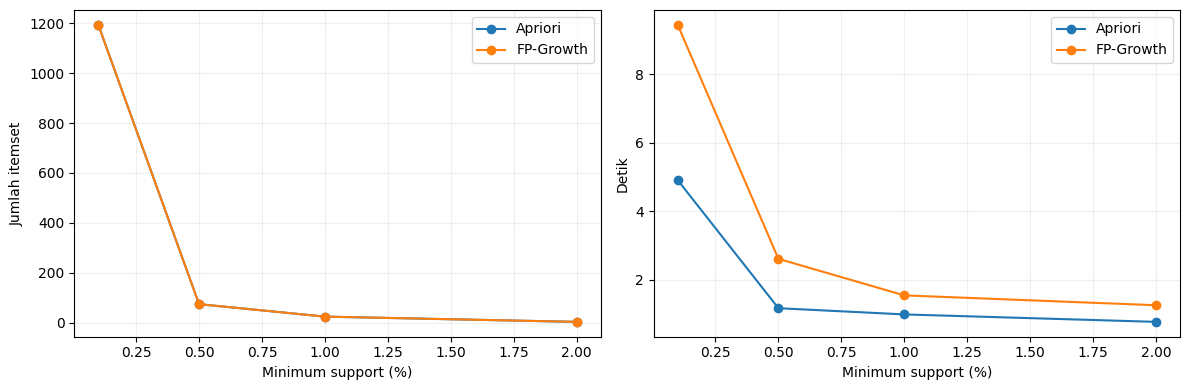

In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
for alg, part in comparison.groupby("algorithm"):
    axes[0].plot(part.min_support * 100, part.itemsets, marker="o", label=alg)
    axes[1].plot(part.min_support * 100, part.seconds, marker="o", label=alg)
axes[0].set(xlabel="Minimum support (%)", ylabel="Jumlah itemset")
axes[1].set(xlabel="Minimum support (%)", ylabel="Detik")
for ax in axes:
    ax.legend()
    ax.grid(alpha=.2)
plt.tight_layout()
plt.show()

## 4. Kesamaan frequent itemsets
Memastikan Apriori dan FP-Growth menghasilkan itemset dan support count yang identik pada setiap minimum support.

In [ ]:
checks = []
for support in SUPPORTS:
    a, f = mining[("Apriori", support)]["itemsets"], mining[("FP-Growth", support)]["itemsets"]
    checks.append({"min_support": support, "itemsets": len(a),
                   "same_itemsets_and_support": dict(zip(a.itemset, a.support_count)) == dict(zip(f.itemset, f.support_count))})
assert all(x["same_itemsets_and_support"] for x in checks), "Apriori dan FP-Growth berbeda, periksa implementasi"
comparison.to_csv(RESULTS / "task6_comparison.csv", index=False)
pd.DataFrame(checks)

,min_support,itemsets,same_itemsets_and_support
0,0.001,1193,True
1,0.005,75,True
2,0.010,25,True
3,0.020,4,True


## 5. Hasil Eksperimen
1. Pengaruh minimum support terhadap performa
Semakin rendah minimum support, semakin banyak frequent itemset, semakin banyak rule, dan semakin lama waktu mining.
Frequent itemset turun dari 1.193 (0,1%) menjadi 75, 25, dan 4 pada 0,5%, 1%, dan 2%, sedangkan rule turun dari 730 menjadi 6, 1, dan 0.
Waktu Apriori turun dari 4,91 detik menjadi 1,16, 0,98, dan 0,76 detik, dan waktu FP-Growth dari 9,44 detik menjadi 2,61, 1,54, dan 1,25 detik (median tiga kali jalan).
Penurunan waktu paling tajam dari 0,1% ke 0,5%, sesudah itu mendatar karena biaya dasar membaca transaksi tidak berubah.

2. Apakah kedua algoritma menghasilkan frequent itemset yang sama?
Ya. Itemset dan support count Apriori dan FP-Growth identik pada keempat minimum support (1.193, 75, 25, dan 4 itemset), dan jumlah rule juga sama.
Pemeriksaannya otomatis dan akan menghentikan notebook jika ada perbedaan.

3. Algoritma yang lebih sesuai untuk dataset DBLP ini
Apriori lebih sesuai pada eksperimen ini karena lebih cepat di semua minimum support, sekitar 1,6 sampai 2,3 kali lebih cepat daripada FP-Growth (misalnya 4,91 detik dibanding 9,44 detik pada 0,1%).
Alasannya transaksi sangat pendek (rata-rata 2,86 item, 57,4% hanya satu item) dan banyak yang identik (hanya 618.049 transaksi berbeda dari 1.822.238), sehingga Apriori berhenti setelah beberapa level dengan kandidat yang sedikit, sedangkan FP-tree hampir tidak menghemat apa-apa karena jarang ada awalan yang sama untuk digabung.
Keunggulan FP-Growth biasanya muncul pada transaksi yang panjang atau support yang sangat rendah, dan itu tidak terjadi pada data ini (itemset terpanjang hanya 5 item).
Keterbatasan: waktu diukur pada implementasi Python sendiri di satu komputer, dan hasilnya bisa berbeda pada implementasi atau mesin lain.

# Bagian E - Temporal Association Analysis
Memakai transaksi Author-Year yang dibagi menjadi empat periode. Support dihitung dengan penyebut jumlah transaksi masing-masing periode, dan ambang support serta confidence dibuat sama untuk semua periode.

## 1. Frequent pattern mining pada setiap periode

### Pembagian periode
Pembagian periode dan jumlah transaksi pada setiap periode. Periode 2024-2025 hanya dua tahun, jadi jumlah transaksinya lebih kecil.

In [ ]:
PERIODS = {"2015-2017": (2015, 2017), "2018-2020": (2018, 2020),
           "2021-2023": (2021, 2023), "2024-2025": (2024, 2025)}
temporal = {}


def run_period(period):
    start, end = PERIODS[period]
    subset = author_year_tx.loc[author_year_tx.year.between(start, end)]
    db = encode_transactions(subset["items"])
    found, seconds = mine(db, "FP-Growth", TEMPORAL_SUPPORT)
    rules = association_rules(found, db.n_transactions)
    temporal[period] = {"transactions": db.n_transactions, "itemsets": found, "rules": rules, "seconds": seconds}
    join_items(found, ["itemset"]).to_csv(RESULTS / f"temporal_itemsets_{start}_{end}.csv", index=False)
    join_items(rules, ["antecedent", "consequent"]).to_csv(RESULTS / f"temporal_rules_{start}_{end}.csv", index=False)
    print(f"{period}: {db.n_transactions:,} transaksi, {len(found):,} itemsets, {len(rules):,} rules, {seconds:.2f} detik")


pd.Series({period: int(author_year_tx.year.between(*span).sum()) for period, span in PERIODS.items()}).to_frame("transaksi")

,transaksi
2015-2017,923118
2018-2020,1081603
2021-2023,1196827
2024-2025,886643


### 2015-2017

In [ ]:
run_period("2015-2017")

2015-2017: 923,118 transaksi, 31 itemsets, 0 rules, 0.33 detik


### 2018-2020

In [ ]:
run_period("2018-2020")

2018-2020: 1,081,603 transaksi, 31 itemsets, 0 rules, 0.35 detik


### 2021-2023

In [ ]:
run_period("2021-2023")

2021-2023: 1,196,827 transaksi, 36 itemsets, 0 rules, 0.43 detik


### 2024-2025

In [ ]:
run_period("2024-2025")

2024-2025: 886,643 transaksi, 47 itemsets, 0 rules, 0.56 detik


## 2. Frequent itemsets pada setiap periode
Sepuluh frequent itemset dengan support tertinggi pada setiap periode.

In [ ]:
def show_period_itemsets(period, n=10):
    return join_items(temporal[period]["itemsets"].head(n).reset_index(drop=True), ["itemset"])

### 2015-2017

In [ ]:
show_period_itemsets("2015-2017")

,itemset,length,support_count,support
0,EMBC,1,17285,0.018725
1,IGARSS,1,13783,0.014931
2,ICC,1,10322,0.011182
3,IECON,1,10010,0.010844
4,ICASSP,1,9921,0.010747
5,IROS,1,8467,0.009172
6,GLOBECOM,1,8356,0.009052
7,ICIP,1,8246,0.008933
8,OFC,1,7959,0.008622
9,CDC,1,7552,0.008181


### 2018-2020

In [ ]:
show_period_itemsets("2018-2020")

,itemset,length,support_count,support
0,IGARSS,1,19200,0.017751
1,EMBC,1,17516,0.016194
2,AAAI,1,14520,0.013425
3,ICASSP,1,14159,0.013091
4,NeurIPS,1,13582,0.012557
5,CVPR,1,12231,0.011308
6,IROS,1,11047,0.010214
7,ICRA,1,10136,0.009371
8,GLOBECOM,1,9231,0.008535
9,IJCAI,1,9048,0.008365


### 2021-2023

In [ ]:
show_period_itemsets("2021-2023")

,itemset,length,support_count,support
0,NeurIPS,1,30990,0.025893
1,CVPR,1,22243,0.018585
2,AAAI,1,21083,0.017616
3,ICASSP,1,20557,0.017176
4,IGARSS,1,19983,0.016697
5,EMBC,1,16012,0.013379
6,ICML,1,14807,0.012372
7,ICCV,1,14365,0.012003
8,ICLR,1,13347,0.011152
9,ICRA,1,13335,0.011142


### 2024-2025

In [ ]:
show_period_itemsets("2024-2025")

,itemset,length,support_count,support
0,NeurIPS,1,43737,0.049329
1,AAAI,1,25689,0.028973
2,ICLR,1,24946,0.028135
3,CVPR,1,23689,0.026718
4,ICML,1,23637,0.026659
5,ICASSP,1,21010,0.023696
6,IROS,1,14552,0.016412
7,EMNLP,1,13908,0.015686
8,ICRA,1,13718,0.015472
9,IJCNN,1,13596,0.015334


## 3. Association rules pada setiap periode
Sepuluh rule dengan lift tertinggi pada setiap periode.

In [ ]:
def show_period_rules(period, n=10):
    rules = temporal[period]["rules"]
    if rules.empty:
        return f"Tidak ada rule pada periode {period}"
    return format_rules(rules.head(n))

### 2015-2017

In [ ]:
show_period_rules("2015-2017")

'Tidak ada rule pada periode 2015-2017'

### 2018-2020

In [ ]:
show_period_rules("2018-2020")

'Tidak ada rule pada periode 2018-2020'

### 2021-2023

In [ ]:
show_period_rules("2021-2023")

'Tidak ada rule pada periode 2021-2023'

### 2024-2025

In [ ]:
show_period_rules("2024-2025")

'Tidak ada rule pada periode 2024-2025'

## 4. Perbandingan association rules antarperiode
Jumlah transaksi, frequent itemset, dan rule pada setiap periode dengan ambang yang sama.

In [ ]:
temporal_summary = pd.DataFrame([
    {"period": period, "transactions": t["transactions"], "itemsets": len(t["itemsets"]),
     "2-itemsets": int((t["itemsets"]["length"] == 2).sum()), "3+-itemsets": int((t["itemsets"]["length"] >= 3).sum()),
     "rules": len(t["rules"]), "seconds": round(t["seconds"], 2)}
    for period, t in temporal.items()
])
temporal_summary.to_csv(RESULTS / "temporal_summary.csv", index=False)
temporal_summary

,period,transactions,itemsets,2-itemsets,3+-itemsets,rules,seconds
0,2015-2017,923118,31,0,0,0,0.33
1,2018-2020,1081603,31,0,0,0,0.35
2,2021-2023,1196827,36,0,0,0,0.43
3,2024-2025,886643,47,5,0,0,0.56


## 5. Pola asosiasi yang bertahan dan yang berubah

### Kombinasi venue yang bertahan
Itemset berisi dua venue atau lebih yang frequent pada semua periode.

In [ ]:
itemset_sets = {period: {frozenset(s) for s in t["itemsets"].loc[t["itemsets"]["length"] >= 2, "itemset"]} for period, t in temporal.items()}
persistent_itemsets = set.intersection(*itemset_sets.values())
print("Kombinasi venue yang frequent di semua periode:", len(persistent_itemsets))
for combo in sorted(persistent_itemsets, key=lambda c: sorted(c))[:20]:
    print(" | ".join(sorted(combo)))

Kombinasi venue yang frequent di semua periode: 0


### Rule yang bertahan
Rule yang muncul di semua periode.

In [ ]:
rule_sets = {period: {(frozenset(a), frozenset(c)) for a, c in zip(t["rules"].antecedent, t["rules"].consequent)}
             for period, t in temporal.items()}
persistent = set.intersection(*rule_sets.values())
print("Rule yang muncul di semua periode:", len(persistent))
for a, c in sorted(persistent, key=lambda pair: (sorted(pair[0]), sorted(pair[1])))[:20]:
    print(" | ".join(sorted(a)), "->", " | ".join(sorted(c)))

Rule yang muncul di semua periode: 0


### Rule yang berubah
Jumlah rule yang hanya muncul pada satu periode.

In [ ]:
pd.Series({
    period: len(ruleset - set.union(*(v for k, v in rule_sets.items() if k != period)))
    for period, ruleset in rule_sets.items()
}).to_frame("rule khusus periode")

,rule khusus periode
2015-2017,0
2018-2020,0
2021-2023,0
2024-2025,0


### Metrik rule yang bertahan
Membandingkan support, confidence, dan lift dari rule yang muncul di semua periode.

In [ ]:
comparison_rows = []
for period, t in temporal.items():
    for _, row in t["rules"].iterrows():
        if (frozenset(row.antecedent), frozenset(row.consequent)) in persistent:
            comparison_rows.append({
                "period": period,
                "antecedent": " | ".join(sorted(row.antecedent)),
                "consequent": " | ".join(sorted(row.consequent)),
                "support": row.support, "confidence": row.confidence, "lift": row.lift,
            })
persistent_metrics = pd.DataFrame(comparison_rows)
if persistent_metrics.empty:
    print("Tidak ada rule yang bertahan di semua periode pada ambang ini.")
else:
    persistent_metrics.to_csv(RESULTS / "temporal_persistent_rules.csv", index=False)
    display(persistent_metrics.sort_values(["antecedent", "consequent", "period"]).head(40))

Tidak ada rule yang bertahan di semua periode pada ambang ini.


Pada minimum support 0,5% per periode, hasilnya sedikit: 31, 31, 36, dan 47 frequent itemset untuk keempat periode, dan tidak ada rule di periode mana pun.
Kombinasi dua venue hanya muncul pada 2024-2025 (lima pasangan), sehingga tidak ada kombinasi venue maupun rule yang bertahan di semua periode, dan tidak ada rule yang khusus muncul di satu periode.
Dengan ambang ini, pola asosiasi antarperiode tidak dapat dibandingkan, dan hal itu tidak berarti pola tersebut tidak ada. Ambang yang lebih rendah dan nama venue yang tidak terpecah per jilid dapat menunjukkan lebih banyak pola.

Yang berubah antarperiode adalah venue tunggal yang frequent dan satu-satunya kumpulan pasangan di 2024-2025:
- 2015-2017: venue teratas adalah EMBC (1,87%), IGARSS, ICC, dan IECON.
- 2018-2020: IGARSS (1,78%), EMBC, AAAI, ICASSP, dan NeurIPS.
- 2021-2023: NeurIPS (2,59%), CVPR, AAAI, ICASSP, dan IGARSS.
- 2024-2025: NeurIPS (4,93%), AAAI, ICLR, CVPR, dan ICML.
- Pasangan 2024-2025: ICLR + NeurIPS (1,04%), ICML + NeurIPS (0,98%), CVPR + NeurIPS (0,77%), ICLR + ICML (0,72%), dan AAAI + NeurIPS (0,71%), seluruhnya venue AI.


## 6. Kemungkinan perubahan tren publikasi berdasarkan hasil eksperimen
Hasil eksperimen menunjukkan pergeseran dari venue rekayasa, sinyal, dan medis ke venue AI.
Pada 2015-2017 venue teratas adalah EMBC, IGARSS, ICC, dan IECON, dan NeurIPS belum masuk 10 besar.
Pada 2024-2025 NeurIPS menjadi yang teratas dengan 4,93% transaksi author-tahun, diikuti AAAI, ICLR, CVPR, dan ICML.
Kenaikan ini sejalan dengan jumlah publikasi NeurIPS yang naik dari 403 (2015) menjadi 5.823 (2025), dan dengan munculnya pasangan venue AI (ICLR + NeurIPS, ICML + NeurIPS, dan lainnya) yang baru melewati minimum support pada 2024-2025.
Kemungkinan penyebabnya pertumbuhan penelitian AI dan jumlah paper yang dikirim, serta semakin banyak author yang menerbitkan di beberapa venue AI sekaligus.
Hal yang perlu diperhatikan: periode 2024-2025 hanya dua tahun, 2025 belum lengkap (IGARSS dan EMBC belum terindeks), jumlah transaksi tiap periode berbeda sehingga yang dibandingkan adalah support dan bukan jumlah mentah, dan tidak ada rule yang ditemukan pada ambang 0,5%, sehingga kesimpulan tren ini berdasarkan itemset dan tidak berdasarkan rule.

# Metadata Eksperimen
Menyimpan konfigurasi, tanggal snapshot, dan versi library run ini ke `results/main/run_metadata.json` agar eksperimen bisa direproduksi.

In [ ]:
metadata = {
    "snapshot_url": snapshot["source"], "snapshot_date": SNAPSHOT_DATE, "retrieved_at": snapshot["retrieved_at"],
    "run_utc": datetime.now(timezone.utc).isoformat(),
    "years": [YEAR_MIN, YEAR_MAX], "support_thresholds": SUPPORTS,
    "minimum_confidence": MIN_CONFIDENCE, "temporal_support": TEMPORAL_SUPPORT,
    "runtime_repeats": RUNTIME_REPEATS, "venue_aliases": VENUE_ALIASES,
    "algorithms": "Apriori, FP-Growth, dan association rules diimplementasikan sendiri di notebook",
    "python": platform.python_version(), "pandas": pd.__version__, "numpy": np.__version__,
}
(RESULTS / "run_metadata.json").write_text(json.dumps(metadata, indent=2, ensure_ascii=False), encoding="utf-8")
con.close()
print("Metadata disimpan di", RESULTS / "run_metadata.json")

Metadata disimpan di c:\MyFolder\Kuliah\Semester 7\Data Mining\Tubes\dblp-conference-mining-team-7\results\main\run_metadata.json
